# Лабораторная работа №2

## Нейросетевой перевод на базе Hugging Face Transformers (MarianMT, NLLB)

**ФИО студента:** Климова Арина Дмитриевна
**Группа:** ИНФА-221
**Вариант:** 6 (**тот же, что в ЛР № 1** — работа сквозная; предметная область: Финансы, банковское дело и платёжные системы)

---

**Цель:** развернуть NMT-пайплайн, исследовать субсловную токенизацию, батчинг, условную
кросс-энтропию и cross-attention, сравнить специализированную EN→RU модель **MarianMT**
с многоязычной **NLLB**.

**Максимум: 20 баллов**

| Критерий | Состав | Баллы |
|---|---|---:|
| Работоспособность пайплайна | MarianMT — 2 · NLLB — 2 · batching/loss/attention — 2 | **6** |
| Корректность лингвистической обработки | языковые коды и токенизация — 2 · объём корпуса (120+ сегментов, 100+ терминов) — 1 · glossary QA — 2 | **5** |
| Анализ ошибок и аргументация | 5+ различий — 2 · интерпретация loss/attention — 2 · вывод — 1 | **5** |
| Оформление и воспроизводимость | результаты и графики — 1 · README — 1 · зависимости — 1 · структура — 1 | **4** |

---

> **Прежде чем запускать код,** прочитайте три следующих раздела: «Суть работы за пять минут», «Связь с ЛР № 1 и место работы в курсе» и «Теоретическое обоснование». Без них блоки 5–8 превращаются в набор непонятных вызовов библиотеки, а интерпретация чисел в отчёте оказывается неверной — это самая частая причина потери баллов по критерию «Анализ ошибок и аргументация».

### Порядок выполнения

1. **Runtime → Change runtime type → T4 GPU.** Без GPU перевод 120 сегментов двумя моделями
   займёт часы.
2. Выполните блоки 0–1 (установка, окружение).
3. Блок 2 — положите в каталог `DATA` **свои** артефакты ЛР № 1: память переводов
   `variant_<N>.tmx` и терминологическую базу `variant_<N>.tbx` (либо их CSV-выгрузки
   `tm_segments_v<N>.csv` и `glossary_smartcat_v<N>.csv`). Блок 2.0 сам преобразует их во
   входные файлы работы; убедитесь, что проверка объёма даёт «ГОТОВО».
4. Реализуйте функции в блоках 3–8 вместо маркеров `# TODO`.
5. Запустите блок 9 — все автотесты должны пройти без `AssertionError`.
6. Выполните блоки 10–15: перевод корпуса, QA, сравнение, **графики**, отчёт.
7. Заполните вручную колонки `preferred` и `comment` — автоматический выбор модели их не
   заменяет.

### Обязательный минимум

| Требование | Значение |
|---|---|
| Сегментов в корпусе, переведённых **каждой** моделью | **120+** |
| Терминов в глоссарии, разобранных токенизаторами | **100+** |
| Пар `source` / `reference` для кросс-энтропии | 5+ |
| Пар для анализа cross-attention | 2+ |
| Режимы инференса | последовательный и пакетный |
| Содержательных различий с аргументацией | 5+ |
| Графиков в отчёте | 4+ |

> Если память переводов из ЛР № 1 меньше требуемого объёма, расширьте в своём ноутбуке ЛР № 1
> списки `PARALLEL_CORPUS` и `TERMS` и перегенерируйте `variant_<N>.tmx` и `variant_<N>.tbx`
> **до** начала этой работы: все дальнейшие выводы опираются на статистику, а на полутора
> десятках сегментов она недостоверна.

### Две особенности актуальных версий библиотек

* **`attn_implementation="eager"`.** Начиная с `transformers` 4.36 при PyTorch ≥ 2.1.1
  по умолчанию подключается ускоренная реализация внимания **SDPA**, которая не обязана
  сохранять веса: в зависимости от версии `outputs.cross_attentions` окажется пустым, и
  блок 7 упадёт с `IndexError: tuple index out of range`. Загружайте модель с явным
  `attn_implementation="eager"`.
* **Предупреждение `max_new_tokens` / `max_length`.** Безобидно (приоритет у
  `max_new_tokens`), но зашумляет вывод — логирование понижается в блоке 1.

## Суть работы за пять минут (читать до запуска кода)

### Что здесь происходит, если совсем коротко

В ЛР № 1 вы собрали **ресурсы переводчика** в форматах CAT-систем: терминологическую базу `variant_<N>.tbx` и память переводов `variant_<N>.tmx` с параллельными сегментами, проверенными человеком. Сейчас те же самые файлы становятся входом: сегменты из памяти переводов прогоняются через **две нейросетевые системы машинного перевода**, терминология из TBX служит эталоном для контроля, а русская часть TMX — эталонным переводом для сравнения.

Работа отвечает на один практический вопрос: **можно ли доверить машине перевод текстов вашей предметной области с утверждённой терминологией — и что именно придётся проверять руками?**

### Четыре явления, которые вы исследуете

| Явление | Вопрос, на который отвечаем | Где в ноутбуке |
|---|---|---|
| **Субсловная токенизация** | Как модель «видит» ваши термины: целиком или обрывками? | блоки 4, 10 |
| **Батчинг** | Сколько стоит перевод по времени и как его ускорить? | блок 6 |
| **Условная кросс-энтропия** | Насколько «привычен» для модели утверждённый перевод? | блок 7 |
| **Cross-attention** | На какие слова оригинала модель смотрела, порождая каждое слово перевода? | блок 8 |

Дальше эти четыре наблюдения складываются в одно прикладное сравнение: **специализированная EN→RU модель MarianMT против многоязычной NLLB** — и в терминологический контроль по вашему глоссарию.

### Что это даёт педагогу как специалисту

Вы получаете не «кнопку перевода», а воспроизводимую процедуру: перевести учебный материал, измерить, где система систематически ошибается на терминах, и оценить объём обязательного постредактирования. Именно так выглядит подготовка локализованного учебного контента в реальной практике: машина делает черновик, человек отвечает за терминологию и смысл.

### Главный вывод, к которому ведёт работа

Беглость перевода и его правильность — **разные вещи**. Нейросеть выдаёт гладкий русский текст, в котором специальный термин может быть искажён, заменён общеупотребительным словом или передан описательно, — и всё это при безупречной грамматике. Найти такие места в переводе своего модуля и есть задача работы. Практическое следствие: терминологический контроль нельзя делегировать модели, он остаётся отдельным этапом работы редактора.

## Связь с ЛР № 1 и место работы в курсе

### Что вы сделали в ЛР № 1 и что из этого берётся сюда

В ЛР № 1 вы работали с форматами CAT-систем: разбирали терминологическую базу **TBX** (ISO 30042), память переводов **TMX** 1.4b, реализовали нечёткий поиск (Fuzzy Match и ICE) и подстановку терминов, а затем выгрузили результаты для Smartcat. На выходе получился комплект файлов — он и есть вход текущей работы.

| Артефакт ЛР № 1 | Что внутри | Во что превращается в ЛР № 2 | Где используется |
|---|---|---|---|
| `variant_<N>.tmx` | единицы перевода `<tu>`: `<seg>` на en и ru, `prop[domain]`, порядок сегментов | `segments_en.csv` (`segment_id`, `source`) и `aligned_reference.csv` (+ `reference`) | вход обеих моделей; эталон для кросс-энтропии и сравнения |
| `variant_<N>.tbx` | `termEntry` → `langSet` en/ru, `<tig>` и `<ntig><termGrp>` | `glossary.csv` (`en`, `ru`) | анализ токенизации и терминологический контроль |
| `glossary_smartcat_v<N>.csv` | `Source (en)`, `Target (ru)`, `Comment` | то же, что TBX (резервный путь) | если XML-файлы не сохранились |
| `tm_segments_v<N>.csv` | `tuid`, `source_segment`, `target_segment`, `domain` | то же, что TMX (резервный путь) | если XML-файлы не сохранились |
| `fuzzy_report_v<N>.csv` | отчёт Fuzzy Match / ICE | в расчётах не участвует | пригодится в выводах: сравнение TM-подстановки и NMT |

Соответствие полей буквальное: `tuid` → `segment_id`, `<seg>` на английском → `source`, `<seg>` на русском → `reference`, английский `<term>` → `en`, русский `<term>` → `ru`. Преобразование выполняет **блок 2.0** — писать его не нужно, но полезно прочитать: там видно, как из XML получается таблица.

### Почему именно эти файлы

* **TMX — это готовый параллельный корпус**, проверенный человеком. Без него нечем считать условную кросс-энтропию и не с чем сравнивать вывод моделей.
* **TBX — утверждённая терминология**. Без неё нечего проверять в терминологическом контроле, а именно он показывает главную слабость нейросетевого перевода.
* **Порядок сегментов в TMX сохраняется** — тот же порядок, который в ЛР № 1 нужен был для контекстного совпадения (ICE). Здесь он даёт связный документ, а не случайный набор фраз.

### Логика курса: три взгляда на одну задачу

```
ЛР № 1  Память переводов и CAT         ЛР № 2  Нейросетевой перевод        далее по курсу
──────────────────────────────         ────────────────────────────        ──────────────────────
TBX: терминология              ───►    токенизация терминов, QA      ───►  метрики качества
TMX: параллельные сегменты     ───►    вход моделей + эталон               BLEU, chrF, COMET
Fuzzy Match / ICE: повторное           кросс-энтропия, внимание            постредактирование
использование перевода                 сравнение Marian и NLLB
```

ЛР № 1 отвечала на вопрос «как **повторно использовать** уже выполненный перевод», ЛР № 2 — «что будет, если перевод **породит модель**», следующая работа курса — «**насколько хорошо** это получилось». Отсюда естественный сюжет для выводов: сегмент с совпадением 100 % (ICE) в ТМ не нуждается в машинном переводе вовсе, а для сегментов без совпадения выбор стоит между NMT с постредактированием и переводом с нуля.

### Объём данных: что делать, если ТМ из ЛР № 1 маленькая

ЛР № 1 не требовала большого корпуса: в эталонном решении получилось 14 единиц перевода и 18 терминов. Для ЛР № 2 нужно **120 сегментов и 100 терминов** — иначе доли соблюдения глоссария и различия моделей статистически недостоверны.

Порядок действий: откройте **свой** ноутбук ЛР № 1, расширьте списки `PARALLEL_CORPUS` и `TERMS` материалами той же предметной области, перегенерируйте `variant_<N>.tmx` и `variant_<N>.tbx` и перенесите их сюда. Код ЛР № 1 при этом не меняется — меняются только данные. Русские соответствия в расширенной части проверяются вручную: `reference` должен остаться переводом, подтверждённым человеком, иначе расчёт кросс-энтропии теряет смысл.

> **О номерах вариантов.** Предметная область берётся из **вашей** ЛР № 1 (в TMX она записана в `prop[@type="domain"]`, в TBX — в `descrip[@type="subjectField"]`), и блок 2.0 печатает её при загрузке. Если нумерация вариантов в таблицах двух работ расходится, ориентируйтесь на предметную область своего комплекта TBX/TMX, а не на номер.

## Теоретическое обоснование

Ниже — минимум теории, который нужен, чтобы понимать, что именно считает код, и корректно интерпретировать числа. Каждый пункт привязан к конкретному блоку ноутбука.

### 1. Что такое нейросетевой перевод (NMT)

Современный перевод — это задача **sequence-to-sequence**: модель получает последовательность токенов исходного языка и порождает последовательность токенов целевого. Архитектура обеих используемых моделей — **энкодер-декодер на основе трансформера** (Vaswani et al., 2017):

* **энкодер** читает весь исходный сегмент и строит для каждой позиции векторное представление с учётом контекста (self-attention);
* **декодер** порождает перевод **по одному токену слева направо**; на каждом шаге он смотрит на уже порождённую часть перевода (self-attention) и на представления оригинала (**cross-attention**);
* выход декодера — распределение вероятностей по всему словарю; из него выбирается следующий токен.

Ключевое отличие от статистического перевода (SMT), с которым знакомились ранее в курсе: в SMT таблицы фраз и модель выравнивания строились явно, а здесь и «словарь соответствий», и «правила перестановки» существуют только как веса сети. Отсюда два следствия, которые вы увидите на практике: система никогда не скажет «не знаю» и выдаст беглый текст даже там, где ошибается.

### 2. Декодирование: как из вероятностей получается текст

Генерация — отдельный алгоритм поверх модели. В работе используется **лучевой поиск (beam search)**: одновременно удерживается несколько гипотез перевода (`num_beams`), на каждом шаге они расширяются и отбираются лучшие по суммарной логарифмической вероятности. Параметры, которые встретятся в коде:

| Параметр | Смысл | Практическое следствие |
|---|---|---|
| `num_beams` | ширина луча | больше — качественнее и медленнее; при 1 это жадный поиск |
| `max_new_tokens` | ограничение длины вывода | защита от зацикливания; приоритетнее `max_length` из конфигурации модели |
| `length_penalty` | штраф за длину | без него beam search систематически предпочитает короткие переводы |
| `do_sample` | случайная выборка | в работе **выключена**: нужна воспроизводимость |

Поэтому перевод в этой работе **детерминирован**: при одних и тех же входе и параметрах результат повторяется. Зафиксированное зерно и `model.eval()` (отключение dropout) — часть того же требования воспроизводимости.

### 3. Субсловная токенизация (блоки 4 и 10)

Словарь модели конечен (у MarianMT — 62 518 единиц, у NLLB — 256 204), а терминология в информатике не ограничена. Решение — **открытый словарь**: редкое слово собирается из частотных фрагментов.

Два основных алгоритма:

* **BPE** (Sennrich et al., 2016) — жадное слияние самых частых пар символов, пока не наберётся заданный размер словаря;
* **Unigram LM** (Kudo, 2018) — вероятностная модель: избыточный словарь постепенно сокращается, остаются единицы, максимизирующие правдоподобие корпуса.

**SentencePiece** (Kudo & Richardson, 2018) — это не алгоритм, а библиотека-обёртка, которая умеет и BPE, и Unigram и работает прямо с сырым текстом, кодируя пробел символом `▁`. Поэтому фраза «Marian = BPE, а NLLB = SentencePiece» некорректна: она противопоставляет алгоритм и инструмент. Правильная формулировка проверяется по классу токенизатора и карточке модели; в документации Hugging Face токенизатор NLLB описан как основанный на **Unigram**, у MarianMT используется собственная реализация поверх SentencePiece.

Что отсюда важно для работы:

1. **Токен ≠ морфема.** Границы получены статистически по корпусу, а не морфологическим анализом: `▁as y mp to tic` не соответствует ни одной морфеме.
2. **Разные словари — разные границы** у одного слова (`▁computation al` против `▁comput ational`), значит, дробление — свойство конкретной модели, а не языка.
3. **Размер словаря не определяет качество дробления на вашем домене.** У NLLB словарь вчетверо больше, но ёмкость распределена между 200 языками, поэтому на английской технической лексике он дробит сильнее. Это частный случай **«проклятия многоязычности»**: при фиксированной ёмкости модели добавление языков ухудшает результат по каждому из них (Conneau et al., 2020).
4. Сильно дробящиеся термины — **кандидаты на нестабильный перевод**; связь дробления и нарушений глоссария вы проверите в блоке 12.

### 4. Условная кросс-энтропия и перплексия (блок 7)

$$\mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T}\log P\left(y_t \mid y_{1:t-1}, x\right)$$

Модель получает исходный сегмент $x$ и **готовую** целевую строку $y$ и на каждом шаге оценивает вероятность фактического следующего токена при условии правильного префикса. Такой режим называется **teacher forcing**: это не генерация, а оценка уже существующей строки — тот же расчёт, что и при обучении.

Технические детали, влияющие на интерпретацию:

* усреднение идёт по токенам целевой строки (паддинг исключается меткой `-100`), поэтому величина **нормирована на длину**;
* удобная эквивалентная форма — **перплексия** $PPL = e^{\mathcal{L}}$: «из скольких равновероятных вариантов модель фактически выбирала». Loss 0.58 — это PPL ≈ 1.8, loss 1.14 — PPL ≈ 3.1;
* `loss_own_output` систематически ниже `loss_reference`: модель по построению считает более вероятным то, что сама и породила. Это свойство декодера, а не превосходство над переводчиком-человеком.

**Чем кросс-энтропия не является.** Это не метрика качества перевода. Она измеряет вероятность конкретной строки при конкретной модели и **несопоставима между моделями с разными словарями**: разные токенизаторы дают разное $T$ и разное пространство событий. Для оценки качества нужны BLEU, chrF и COMET — они появятся в следующей работе курса. Полезная же роль loss здесь диагностическая: высокий `loss_reference` отмечает сегменты, где утверждённый перевод расходится с «привычным» для модели, — обычно это места с терминологией.

### 5. Cross-attention (блок 8)

Веса внимания декодера к позициям оригинала образуют тензор формы `[batch, heads, target_len, source_len]`. После усреднения по головам получается матрица, внешне похожая на матрицу выравнивания слов из статистического перевода.

Как её корректно читать:

* **диагональная структура** говорит о том, что порядок порождения в целом следует порядку оригинала; отклонения от диагонали отмечают перестановки;
* заметная доля массы регулярно уходит на **служебные токены** (`</s>`) — это не переводческое соответствие, а поведение сети;
* **attention — диагностический сигнал, а не объяснение**. В литературе это прямо показано: веса внимания не обязаны совпадать с важностью входов (Jain & Wallace, 2019), возможны альтернативные распределения весов с тем же предсказанием (Wiegreffe & Pinter, 2019), а роли голов различаются и часть из них избыточна (Voita et al., 2019). Утверждение «эта голова выучила правило перевода» из одной тепловой карты не следует.

**Техническое условие.** Веса внимания возвращает только «наивная» реализация (`eager`). Начиная с `transformers` 4.36 при PyTorch ≥ 2.1.1 по умолчанию подключается ускоренная реализация **SDPA**, которая сохранять веса не обязана: в зависимости от версии библиотека либо сама откатывается на `eager` с предупреждением, либо возвращает пустой кортеж `cross_attentions`, и код падает с `IndexError`. Поэтому модель загружается с явным `attn_implementation="eager"`.

### 6. Батчинг, паддинг и время инференса (блок 6)

Пакетная обработка ускоряет перевод, потому что графический процессор эффективен на крупных матричных операциях: вместо множества мелких вызовов выполняется один большой. Плата за это — **паддинг**: короткие сегменты дополняются до длины самого длинного в пачке, и часть вычислений тратится на заполнители. Отсюда два наблюдаемых эффекта:

* **насыщение** — при росте размера пачки прирост скорости падает;
* **возможные расхождения результата** между режимами: паддинг меняет числа в маскируемых позициях, и beam search на границе может выбрать другую гипотезу. Это не ошибка реализации, но причина фиксировать режим инференса в отчёте.

Различайте **задержку** (время одного сегмента, важна для интерактивного перевода) и **пропускную способность** (сегментов в секунду, важна для пакетной локализации модуля). Батчинг улучшает второе.

### 7. Специализированная модель против многоязычной (блоки 9, 13)

| | MarianMT `Helsinki-NLP/opus-mt-en-ru` | NLLB `facebook/nllb-200-distilled-600M` |
|---|---|---|
| Охват | одна пара EN→RU | 200 языков |
| Параметры | ≈ 76 млн | ≈ 615 млн |
| Происхождение | обучена на корпусах OPUS (Tiedemann & Thottingal, 2020) | дистиллированная версия большой модели NLLB-200 (NLLB Team, 2022) |
| Направление перевода | задано самой моделью | задаётся **кодами языков**: `src_lang` и `forced_bos_token_id` |

**Дистилляция** означает, что компактная модель обучалась воспроизводить поведение более крупной: это способ сохранить значительную часть качества при меньших ресурсах.

**Механизм языковых кодов** стоит понимать буквально: у многоязычной модели декодер начинает генерацию со специального токена целевого языка. Если его не задать, язык результата не определён — в эталонном прогоне без `forced_bos_token_id` модель выдала испанский перевод. Коды берутся из схемы FLORES-200 (`eng_Latn`, `rus_Cyrl`) и являются частью контракта модели, а не декоративным параметром.

### 8. Терминологический контроль (блок 12)

Для учебного модуля единообразие терминологии важнее стилистической гладкости: если в одном абзаце «вычислительная сложность», а в другом «расчётная сложность», студент решит, что речь о разных понятиях. NMT-модель общего назначения такого единообразия не гарантирует — она оптимизирует вероятность строки, а не соответствие вашему глоссарию.

Отсюда требования к процедуре QA:

* **знаменатель** — число фактических вхождений терминов в исходные сегменты, а не все пары «сегмент × термин», иначе доля соблюдения искусственно завышается;
* **русская морфология** ломает точное строковое сравнение («сложность» → «сложности», «сложностью»), поэтому сравнение ведётся по основе, а каждое срабатывание подтверждается вручную;
* строковая проверка даёт и **ложные срабатывания** (корректный синоним, смена части речи при перестройке предложения), и **пропуски** (термин передан описательно). Автоматическая цифра без ручного подтверждения в отчёт не выносится.

В профессиональной практике этот этап стандартизован: требования к процессу перевода описывает ISO 17100:2015, а к полному постредактированию машинного перевода — ISO 18587:2017. Ваша колонка `confirmed` — учебный аналог того самого постредакторского решения.

### 9. Типология различий и ошибок (блоки 13–14)

Чтобы сравнение моделей не сводилось к «мне больше нравится», различия классифицируются. Удобная опора — типология MQM (Lommel et al., 2014), из которой для этой работы достаточно четырёх категорий:

| Категория | Что это | Как выглядит на практике |
|---|---|---|
| **Точность (accuracy)** | искажение смысла оригинала | многозначное слово переведено неверным значением, отрицание или число потеряны |
| **Терминология** | отклонение от утверждённого в ЛР № 1 глоссария | вместо принятого термина — синоним, калька или описательный оборот |
| **Беглость (fluency)** | грамматика и согласование | придаточное отнесено не к тому члену предложения, нарушено управление |
| **Стиль и синтаксис** | допустимая, но нежелательная перестройка | термин из подлежащего определения превращён в обстоятельство |

Именно эта классификация превращает колонку `comment` из мнения в аргумент.

## Блок 0. Установка зависимостей

`torch` в Colab предустановлен. Ставим `transformers`, `sentencepiece` (нужен токенизатору
NLLB) и `sacremoses` (предобработка MarianMT).

In [1]:
!pip install -q "transformers>=4.40" sentencepiece sacremoses

## Блок 1. Окружение и структура каталогов

Ячейка готова — менять её не нужно. Зафиксированное зерно и вывод версий обязательны для
воспроизводимости (критерий 4).

In [2]:
from __future__ import annotations

import json
import platform
import random
import time
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

transformers.logging.set_verbosity_error()   # убирает предупреждение о max_length

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE = Path("/content/lab02") if Path("/content").exists() else Path.cwd() / "lab02"
DATA = BASE / "data"
RESULTS = BASE / "results"
FIGURES = BASE / "figures"
for folder in (DATA, RESULTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MARIAN_NAME = "Helsinki-NLP/opus-mt-en-ru"
NLLB_NAME = "facebook/nllb-200-distilled-600M"
SRC_LANG, TGT_LANG = "eng_Latn", "rus_Cyrl"

MIN_SEGMENTS, MIN_TERMS = 120, 100

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

ENVIRONMENT = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "-",
}
for key, value in ENVIRONMENT.items():
    print(f"{key:>13}: {value}")
print(f"{'base_dir':>13}: {BASE}")
if DEVICE.type != "cuda":
    print("\nВНИМАНИЕ: GPU не подключён. Runtime -> Change runtime type -> T4 GPU.")

       python: 3.13.16
        torch: 2.11.0+cu130
 transformers: 5.21.0
       device: cuda
          gpu: Tesla T4
     base_dir: /content/lab02


## Блок 2. Данные: артефакты ЛР № 1 (TBX и TMX)

**Что нужно подготовить.** Вход работы — файлы, которые вы уже сдавали в ЛР № 1:

| Файл ЛР № 1 | Обязателен | Что из него берётся |
|---|---|---|
| `variant_<N>.tmx` — память переводов | да (или CSV-замена) | параллельные сегменты: английский `<seg>` → `source`, русский `<seg>` → `reference`, `tuid` → `segment_id` |
| `variant_<N>.tbx` — терминологическая база | да (или CSV-замена) | термины: английский `<term>` → `en`, русский `<term>` → `ru` |
| `tm_segments_v<N>.csv` | резервный путь | колонки `tuid`, `source_segment`, `target_segment` |
| `glossary_smartcat_v<N>.csv` | резервный путь | колонки `Source (en)`, `Target (ru)` |

XML-файлы предпочтительнее: в них сохранены порядок сегментов, коды языков и предметная область (`prop[@type="domain"]`), а CSV-выгрузка часть этого теряет.

**Как положить файлы в среду.** В ячейке блока 2.0 закомментированы две заготовки: загрузка с компьютера через `files.upload()` и копирование из Google Drive. Второй способ удобнее: файлы переживут перезапуск среды Colab.

**Что произойдёт дальше.** Блок 2.0 (адаптер) прочитает ваши TBX и TMX и соберёт три файла в каталоге `DATA`: `segments_en.csv`, `glossary.csv`, `aligned_reference.csv`. Следующая ячейка их прочитает и проверит структуру и объём. Если артефакты ЛР № 1 не найдены, создаётся **демонстрационный** мини-набор: он годится только для проверки автотестов, сдавать работу на нём нельзя.

**Требуемый объём: 120 сегментов и 100 терминов.** В ЛР № 1 корпус мог быть меньше (в эталоне — 14 сегментов и 18 терминов). Тогда откройте свой ноутбук ЛР № 1, дополните списки `PARALLEL_CORPUS` и `TERMS` материалами той же предметной области, перегенерируйте `variant_<N>.tmx` и `variant_<N>.tbx` и вернитесь сюда. Русские соответствия в добавленной части проверьте вручную: `reference` должен остаться переводом, подтверждённым человеком.

**На что смотреть в выводе.** Имена источников, число сегментов и терминов, предметная область из вашего TMX и строку «ГОТОВО» проверки объёма.

### Блок 2.0. Адаптер артефактов ЛР № 1

> Ячейка ниже содержит готовый адаптер: функции `tmx_to_pairs()` и `tbx_to_glossary()` разбирают XML стандартов TMX 1.4b и TBX (ISO 30042) теми же приёмами, что и ЛР № 1, а `build_lab02_inputs()` собирает три входных файла работы.

Ячейка готова — менять её не нужно. Если файлы ЛР № 1 не найдены, адаптер сообщит об этом и следующая ячейка создаст демонстрационный набор для проверки автотестов.

In [3]:
# ============================================================================
#  Блок 2. Генерация файлов variant_6.tbx и variant_6.tmx
# ============================================================================
import xml.etree.ElementTree as ET
from pathlib import Path

# Берем DATA из памяти, если она есть, иначе создаем папку
if 'DATA' not in globals():
    DATA = Path("/content/lab02/data") if Path("/content").exists() else Path.cwd() / "lab02" / "data"
    DATA.mkdir(parents=True, exist_ok=True)

XML_LANG = "{http://www.w3.org/XML/1998/namespace}lang"

PARALLEL_V6 = [
    ("Микрофинансовая организация предоставляет небольшие займы предпринимателям с низким доходом.", "The microfinance institution provides small loans to low-income entrepreneurs."),
    ("Микрокредит помогает заемщикам начать или расширить свой малый бизнес.", "Microcredit helps borrowers start or expand their small businesses."),
    ("Активный портфель займов вырос на 15% за последний квартал.", "The active loan portfolio grew by 15% over the last quarter."),
    ("График погашения согласовывается до выдачи займа.", "A repayment schedule is agreed upon before the loan is disbursed."),
    ("Резерв на убытки по займам покрывает ожидаемые невозвраты в портфеле.", "The loan-loss provision covers expected defaults in the portfolio."),
    ("Финансовая самоокупаемость означает покрытие всех расходов за счет операционного дохода.", "Financial self-sufficiency means covering all costs from operating income."),
    ("Гарантийный депозит часто требуется в качестве залога по займу.", "Compulsory savings are often required as collateral for a loan."),
    ("Групповое кредитование использует солидарную ответственность для обеспечения возврата.", "Group-based lending uses joint liability to ensure repayment."),
    ("Коэффициент операционных расходов измеряет административную эффективность.", "The operating expense ratio measures administrative efficiency."),
    ("Маржа процентной ставки должна покрывать стоимость привлеченных средств и риск.", "Interest rate margins must cover the cost of funds and risk."),
    ("Денежные средства организации хранятся на расчетном счете.", "An organization's cash is held in a current account."),
    ("Заемщик, просрочивший выплаты, может столкнуться с судебным иском и пеней.", "A borrower in default may face legal action and penalty interest."),
    ("Балансовый отчет показывает активы, обязательства и собственный капитал.", "The balance sheet shows assets, liabilities, and equity."),
    ("Анализ денежных потоков помогает оценить ликвидность организации.", "Cash flow analysis helps assess the liquidity of the institution."),
    ("Аудиторский отчет содержит заключение о финансовой отчетности.", "The audit report provides an opinion on the financial statements."),
    ("Операционная самоокупаемость достигается, когда доходы покрывают операционные расходы.", "Operational sustainability is achieved when revenues cover operating costs."),
    ("Индикатор социальной эффективности измеряет глубину охвата.", "The social performance indicator measures depth of outreach."),
    ("Сберегательные счета позволяют клиентам безопасно вносить и снимать средства.", "Savings accounts allow clients to deposit and withdraw funds safely."),
    ("Кредитный специалист оценивает кредитоспособность каждого заявителя.", "The loan officer assesses the creditworthiness of each applicant."),
    ("Финансовая отчётность должна составляться в соответствии с применимыми стандартами.", "Financial statements must be prepared in accordance with applicable standards."),
    ("Бизнес-план описывает цели, стратегии и финансовые прогнозы компании.", "A business plan describes the objectives, strategies, and financial forecasts of a company."),
    ("Бенчмаркинг позволяет сравнить показатели организации с показателями других участников рынка.", "Benchmarking allows an organization to compare its performance with that of other market participants."),
    ("Финансовая маржа показывает разницу между финансовыми доходами и расходами.", "Financial margin shows the difference between financial income and financial costs."),
    ("Операционная прибыль не учитывает проценты и налоги.", "Operating profit does not take interest and taxes into account."),
    ("Чистая прибыль остается после вычета всех расходов и налогов.", "Net profit remains after all expenses and taxes have been deducted."),
    ("Норма прибыли показывает отношение чистой прибыли к выручке.", "Profit margin shows the ratio of net income to revenue."),
    ("Банкротство наступает, когда организация не может выполнять свои долговые обязательства.", "Insolvency occurs when an organization cannot meet its debt obligations."),
    ("Оборот кредитного портфеля показывает, как быстро займы погашаются и заменяются новыми.", "Loan portfolio turnover shows how quickly loans are repaid and replaced by new ones."),
    ("Качество портфеля оценивается по уровню возврата и просрочек.", "Portfolio quality is assessed by repayment and delinquency levels."),
    ("Расходы на персонал включают заработную плату, льготы и обучение.", "Personnel expenses include wages, benefits, and training."),
    ("Административные расходы связаны с общим управлением организацией.", "Administrative expenses are related to the general management of an organization."),
    ("Просроченный заем возникает, когда заемщик не вносит платежи в срок.", "A defaulted loan arises when the borrower fails to make payments on time."),
    ("Безнадежный долг списывается как убыток, поскольку его невозможно взыскать.", "A bad debt is written off as a loss because it cannot be collected."),
    ("Просроченная задолженность фиксируется, когда платеж по займу не внесен вовремя.", "Delinquency is recorded when a loan payment is not made on time."),
    ("Эффективная процентная ставка учитывает начисление сложных процентов и все комиссии.", "The effective interest rate takes compounding and all fees into account."),
    ("Государственный банк развития финансирует проекты в интересах общества.", "A public development bank finances projects in the public interest."),
    ("Депозитный сертификат — это срочный вклад с фиксированной ставкой, выпущенный банком.", "A certificate of deposit is a time deposit with a fixed rate issued by a bank."),
    ("Риск ликвидности связан с неспособностью выполнить краткосрочные обязательства.", "Liquidity risk is related to the inability to meet short-term obligations."),
    ("Валютный риск возникает из-за изменения обменных курсов.", "Currency risk arises from changes in exchange rates."),
    ("Требования к капиталу устанавливают минимальный уровень собственных средств банка.", "Capital requirements set the minimum level of a bank's own funds."),
    ("Обязательный резерв банки формируют в соответствии с требованиями регулятора.", "Legal reserves are formed by banks in accordance with regulatory requirements."),
    ("Списание актива происходит, когда его невозможно взыскать.", "A write-off of an asset occurs when it cannot be collected."),
    ("График старения группирует займы по срокам просрочки.", "An aging schedule groups loans by the length of overdue payments."),
    ("Задолженность — это суммы, не выплаченные в срок по займу.", "Arrears are amounts not paid on time under a loan."),
    ("Пеня начисляется на просроченные платежи по займу.", "Penalty interest is charged on overdue loan payments."),
    ("Инкассо — это процесс взыскания просроченных платежей с заемщиков.", "Collection is the process of recovering overdue payments from borrowers."),
    ("Возврат ранее списанного займа улучшает финансовое состояние организации.", "Recovery of a previously written-off loan improves the financial position of the organization."),
    ("Микрофинансирование предоставляет финансовые услуги малообеспеченным слоям населения.", "Microfinance provides financial services to low-income individuals."),
    ("Микрозайм обычно выдается на короткий срок.", "A microloan is typically provided for a short duration."),
    ("Микропредприниматель часто работает без наемных сотрудников.", "A microentrepreneur often works without hired employees."),
    ("Микрострахование предназначено для людей с низким доходом.", "Micro-insurance is designed for low-income individuals."),
    ("Активный заем находится на стадии погашения.", "An active loan is at the stage of repayment."),
    ("Активный заемщик имеет непогашенный остаток по займу.", "An active borrower has an outstanding loan balance."),
    ("Частота выплат может быть еженедельной или ежемесячной.", "Repayment frequency can be weekly or monthly."),
    ("Заем с погашением всей основной суммы в конце срока требует крупного платежа при наступлении срока.", "A balloon loan requires a large payment at maturity."),
    ("Возобновляемый кредит можно использовать повторно в пределах лимита.", "Revolving credit can be used repeatedly within a limit."),
    ("Заем на пополнение оборотного капитала финансирует ежедневные операции.", "A working-capital loan finances daily operations."),
    ("Группа солидарной ответственности создает давление на заемщиков для возврата.", "A joint-liability group creates pressure on borrowers to repay."),
    ("Группа взаимопомощи объединяет людей, которые сберегают и одалживают друг другу.", "A self-help group brings together people who save and lend to each other."),
    ("Вклад приносит проценты вкладчику.", "A deposit earns interest for the depositor."),
    ("Вкладчик размещает деньги на депозитном счете.", "A depositor places money in a deposit account."),
    ("Процентная ставка выражается как годовая ставка.", "The interest rate is expressed as an annual rate."),
    ("Метод начисления процентов на первоначальную сумму рассчитывает проценты от исходной суммы.", "The flat method calculates interest on the original principal."),
    ("Метод начисления процентов на остаток задолженности снижает проценты по мере погашения.", "The declining-balance method reduces interest as the loan is repaid."),
    ("Чистая процентная маржа показывает прибыльность кредитования.", "Net interest margin shows the profitability of lending."),
    ("Финансовая устойчивость позволяет организации выполнять свои обязательства.", "Financial viability allows an organization to meet its obligations."),
    ("Индикатор охвата показывает, насколько организация обслуживает целевую аудиторию.", "The outreach indicator shows how well an organization serves its target population."),
    ("Анализ воздействия оценивает изменения в жизни клиентов.", "Impact analysis assesses changes in clients' lives."),
    ("Анализ коэффициентов используется для оценки ликвидности и рентабельности.", "Ratio analysis is used to evaluate liquidity and profitability."),
    ("Анализ безубыточности определяет точку, где доходы равны расходам.", "Break-even analysis determines the point where revenue equals costs."),
    ("Отчет о прибылях и убытках показывает доходы и расходы за период.", "The income statement shows revenues and expenses over a period."),
    ("Отчет о движении денежных средств отражает притоки и оттоки денег.", "The cash flow statement reflects cash inflows and outflows."),
    ("Внешний аудит проводится независимой стороной.", "An external audit is conducted by an independent party."),
    ("Внутренний аудит оценивает внутренний контроль и соответствие требованиям.", "An internal audit assesses internal controls and compliance."),
    ("Внутренний контроль защищает активы и обеспечивает точность отчетности.", "Internal control safeguards assets and ensures accurate reporting."),
    ("Бухгалтерский учет методом начисления фиксирует доходы и расходы при их возникновении.", "Accrual accounting records revenues and expenses when they are incurred."),
    ("Кассовый метод ведения бухгалтерского учета фиксирует операции только при движении денег.", "Cash accounting records transactions only when cash is received or paid."),
    ("Бухгалтерский учет на основе двойной записи требует равенства дебета и кредита.", "Double-entry bookkeeping requires equal debits and credits."),
    ("Главная книга содержит все финансовые операции по счетам.", "The general ledger contains all financial transactions by account."),
    ("Пробный баланс проверяет, что дебет равен кредиту.", "The trial balance checks that debits equal credits."),
    ("Оборотные активы используются в течение года.", "Current assets are used within one year."),
    ("Основные средства используются в операциях длительное время.", "Fixed assets are used in operations for a long time."),
    ("Аккумулированная накопленная прибыль реинвестируется в бизнес.", "Retained earnings are reinvested in the business."),
    ("Оборотный капитал измеряет краткосрочную ликвидность.", "Working capital measures short-term liquidity."),
    ("Ликвидность — это способность выполнять краткосрочные обязательства.", "Liquidity is the ability to meet short-term obligations."),
    ("Платежеспособность — это способность выполнять долгосрочные обязательства.", "Solvency is the ability to meet long-term obligations."),
    ("Левередж использует заемные средства для повышения доходности.", "Leverage uses borrowed funds to increase returns."),
    ("Мультипликатор собственного капитала равен отношению активов к капиталу.", "The equity multiplier equals assets divided by equity."),
    ("Рентабельность активов измеряет чистую прибыль на единицу активов.", "Return on assets measures net income per unit of assets."),
    ("Валовая прибыль равна выручке минус себестоимость.", "Gross margin equals revenue minus cost of goods sold."),
    ("Возмещение затрат показывает, насколько доходы покрывают расходы.", "Cost recovery shows how well revenue covers costs."),
    ("Субсидия снижает затраты организации.", "A subsidy reduces an organization's costs."),
    ("Заинтересованные стороны включают клиентов, сотрудников и регуляторов.", "Stakeholders include clients, staff, and regulators."),
    ("Управление определяет системы и процессы руководства организацией.", "Governance defines the systems and processes for directing an organization."),
    ("Внеофисное банковское обслуживание использует мобильные и агентские сети.", "Branchless banking uses mobile and agent networks."),
    ("Мобильный банкинг доступен через смартфон или планшет.", "Mobile banking is available via a smartphone or tablet."),
    ("Денежный перевод отправляется мигрантами на родину.", "A remittance is sent by migrants to their home country."),
    ("Ипотека обеспечена недвижимостью.", "A mortgage is secured by real estate."),
    ("Жилищное микрофинансирование помогает малообеспеченным домохозяйствам улучшить жилье.", "Housing microfinance helps low-income households improve their housing."),
    ("Жилищный кредит используется для покупки, строительства или ремонта жилья.", "A home loan is used to purchase, build, or renovate a home."),
    ("Операционный риск связан с ошибками в бизнес-процессах.", "Operational risk is related to errors in business processes."),
    ("Анализ затрат и результатов помогает оценить выгоду от проекта.", "Cost-benefit analysis helps evaluate the benefits of a project."),
    ("Акционерный капитал является частью собственных средств организации.", "Equity is part of an organization's own funds."),
    ("Апексная организация предоставляет финансирование сети микрофинансовых организаций.", "An apex institution provides funding to a network of microfinance institutions."),
    ("Валовой финансовый результат показывает разницу между финансовыми доходами и расходами.", "Gross financial margin shows the difference between financial income and costs."),
    ("Внутренняя норма доходности используется для оценки инвестиционных проектов.", "Internal rate of return is used to evaluate investment projects."),
    ("Даунскойлинг — это выход коммерческих банков на рынок микрофинансовых клиентов.", "Downscaling is the entry of commercial banks into the microfinance market."),
    ("Индекс зависимости от субсидий показывает, насколько организация зависит от грантов.", "The subsidy dependence index shows how much an organization depends on grants."),
    ("Индивидуальное кредитование предполагает выдачу займов отдельным заемщикам.", "Individual lending involves issuing loans to individual borrowers."),
    ("Инфляция — это снижение стоимости денег относительно общего количества и производства.", "Inflation is the decrease in value of money relative to overall quantity and production."),
    ("Материальность (аудит) определяет значимость ошибки для финансовой отчетности.", "Materiality (audit) determines the significance of an error for financial statements."),
    ("Минимальные требования к капиталу устанавливают минимальный уровень собственных средств.", "Minimum capital requirements set the minimum level of own funds."),
    ("Мониторинг и оценка позволяют отслеживать эффективность программы.", "Monitoring and evaluation allow tracking the effectiveness of a program."),
    ("Операционная эффективность отражает соотношение затрат и результатов деятельности.", "Operational efficiency reflects the ratio of costs to activity results."),
    ("Паника — это экономический спад, обычно сопровождаемый тревогой по поводу валюты.", "A panic is an economic downturn usually accompanied by anxiety over currency."),
    ("Рецессия — это продолжающееся несколько месяцев снижение экономической активности и ВВП.", "A recession is a multi-month decline in economic activity and GDP."),
    ("Кредитный фонд аккумулирует средства для выдачи займов.", "A loan fund pools capital for lending."),
    ("Денежный поток отражает движение средств компании.", "Cash flow reflects the movement of funds in a company."),
    ("Выдача займа происходит после одобрения заявки.", "Loan disbursement occurs after the application is approved."),
    ("Кредитная история заемщика влияет на решение банка.", "The borrower's credit history influences the bank's decision.")
]

TERMS_V6 = [
    {"en": "microfinance institution", "ru": "микрофинансовая организация", "pos": "noun", "def_en": "An organization that provides financial services to low-income clients, often referred to as an MFI."},
    {"en": "microcredit", "ru": "микрокредит", "pos": "noun", "def_en": "A small loan given to a low-income individual to help them become self-employed or grow a small business."},
    {"en": "active loan portfolio", "ru": "активный портфель займов", "pos": "noun", "def_en": "The total principal amount of all loans currently outstanding and owed to a lender."},
    {"en": "repayment schedule", "ru": "график погашения", "pos": "noun", "def_en": "A schedule specifying the amounts and dates for repaying a loan."},
    {"en": "loan-loss provision", "ru": "резерв на убытки по займам", "pos": "noun", "def_en": "An expense set aside to cover expected losses from loans that may not be repaid."},
    {"en": "financial self-sufficiency", "ru": "финансовая самоокупаемость", "pos": "noun", "def_en": "The ability to cover all costs, including the cost of capital, from operating income without subsidies."},
    {"en": "compulsory savings", "ru": "гарантийный депозит", "pos": "noun", "def_en": "Savings that borrowers are required to deposit as a condition for obtaining a loan, often held as collateral."},
    {"en": "group-based lending", "ru": "групповое кредитование", "pos": "noun", "def_en": "A lending methodology where loans are made to individuals within a group that shares liability for repayment."},
    {"en": "administrative efficiency", "ru": "административная эффективность", "pos": "noun", "def_en": "The effectiveness with which an organization uses its administrative resources."},
    {"en": "interest rate margin", "ru": "маржа процентной ставки", "pos": "noun", "def_en": "The difference between the interest rate charged on loans and the rate paid on borrowed funds."},
    {"en": "cash", "ru": "денежные средства", "pos": "noun", "def_en": "Money in the form of bills or coins, or available in a bank account."},
    {"en": "borrower in default", "ru": "заемщик, просрочивший выплату", "pos": "noun", "def_en": "A borrower who has failed to meet the legal obligations of a loan agreement."},
    {"en": "balance sheet", "ru": "балансовый отчет", "pos": "noun", "def_en": "A financial statement showing assets, liabilities, and equity at a specific point in time."},
    {"en": "cash flow analysis", "ru": "анализ денежных потоков", "pos": "noun", "def_en": "Examination of the inflows and outflows of cash to assess liquidity and financial health."},
    {"en": "audit report", "ru": "аудиторский отчет", "pos": "noun", "def_en": "A written document presenting the auditor's findings and opinion on financial statements."},
    {"en": "operational sustainability", "ru": "операционная самоокупаемость", "pos": "noun", "def_en": "The ability of an institution to cover its operating costs from its operating income."},
    {"en": "depth of outreach", "ru": "глубина охвата", "pos": "noun", "def_en": "The level of poverty of the clients served by a microfinance institution."},
    {"en": "savings account", "ru": "сберегательный счет", "pos": "noun", "def_en": "A deposit account held at a financial institution that earns interest and is used to store funds."},
    {"en": "loan officer", "ru": "кредитный специалист", "pos": "noun", "def_en": "A staff member who works directly with borrowers, assessing loans and collecting repayments."},
    {"en": "audited financial statements", "ru": "финансовые отчеты, прошедшие аудиторскую проверку", "pos": "noun", "def_en": "Financial statements that have been examined and verified by an independent auditor."},
    {"en": "business plan", "ru": "бизнес-план", "pos": "noun", "def_en": "A written document describing a business's objectives, strategies, and financial forecasts."},
    {"en": "benchmarking", "ru": "бенчмаркинг", "pos": "noun", "def_en": "Comparing an organization's performance metrics with those of peers or industry standards."},
    {"en": "financial margin", "ru": "финансовая маржа", "pos": "noun", "def_en": "The difference between financial income and financial costs, indicating profitability from lending."},
    {"en": "operating profit", "ru": "операционная прибыль", "pos": "noun", "def_en": "Profit from core business operations, excluding interest and taxes."},
    {"en": "net profit", "ru": "чистая прибыль", "pos": "noun", "def_en": "The amount of profit remaining after all expenses and taxes have been deducted."},
    {"en": "profit margin", "ru": "норма прибыли", "pos": "noun", "def_en": "The ratio of net income to revenue, indicating profitability."},
    {"en": "insolvency", "ru": "банкротство", "pos": "noun", "def_en": "A financial state where an organization cannot meet its debt obligations as they come due."},
    {"en": "loan portfolio turnover", "ru": "оборот кредитного портфеля", "pos": "noun", "def_en": "The rate at which loans in a portfolio are repaid and replaced by new loans over a given period."},
    {"en": "portfolio quality", "ru": "качество портфеля", "pos": "noun", "def_en": "A measure of the credit risk in a loan portfolio, often assessed by repayment rates and arrears levels."},
    {"en": "personnel expenses", "ru": "расходы на персонал", "pos": "noun", "def_en": "Costs associated with employing staff, including wages, benefits, and training."},
    {"en": "administrative expenses", "ru": "административные расходы", "pos": "noun", "def_en": "Costs related to the general administration and management of an organization."},
    {"en": "defaulted loan", "ru": "просроченный заем", "pos": "noun", "def_en": "A loan on which the borrower has failed to make scheduled payments for a specified period."},
    {"en": "bad debt", "ru": "безнадежный долг", "pos": "noun", "def_en": "A loan that is considered uncollectible and is written off as a loss."},
    {"en": "delinquency", "ru": "просроченная задолженность", "pos": "noun", "def_en": "The state of being overdue on a loan payment."},
    {"en": "effective interest rate", "ru": "эффективная процентная ставка", "pos": "noun", "def_en": "The true cost of borrowing, taking into account compounding and all fees over a year."},
    {"en": "public development bank", "ru": "государственный банк развития", "pos": "noun", "def_en": "A government-owned financial institution that provides funding for development projects."},
    {"en": "certificate of deposit", "ru": "депозитный сертификат", "pos": "noun", "def_en": "A time deposit with a fixed term and interest rate, issued by a bank."},
    {"en": "liquidity risk", "ru": "риск ликвидности", "pos": "noun", "def_en": "The risk that an organization cannot meet its short-term financial obligations."},
    {"en": "currency risk", "ru": "валютный риск", "pos": "noun", "def_en": "The risk of financial loss from changes in exchange rates between currencies."},
    {"en": "capital requirements", "ru": "требования к капиталу", "pos": "noun", "def_en": "Minimum levels of capital that financial institutions must maintain as required by regulators."},
    {"en": "legal reserves", "ru": "обязательный резерв", "pos": "noun", "def_en": "Funds that financial institutions are required by law to set aside as a safety buffer."},
    {"en": "write-off", "ru": "списание", "pos": "noun", "def_en": "The removal of an asset from the balance sheet when it is deemed uncollectible."},
    {"en": "aging schedule", "ru": "график старения", "pos": "noun", "def_en": "A report that categorizes loans by the length of time payments are overdue."},
    {"en": "arrears", "ru": "задолженность", "pos": "noun", "def_en": "Unpaid amounts that are past due on a loan."},
    {"en": "penalty interest", "ru": "пеня", "pos": "noun", "def_en": "Additional interest charged on overdue loan payments as a penalty."},
    {"en": "collection", "ru": "инкассо", "pos": "noun", "def_en": "The process of recovering overdue loan payments from borrowers."},
    {"en": "recovery", "ru": "возврат", "pos": "noun", "def_en": "The collection of loan amounts that were previously considered uncollectible."},
    {"en": "microfinance", "ru": "микрофинансирование", "pos": "noun", "def_en": "Provision of financial services such as loans, savings, and insurance to low-income individuals."},
    {"en": "microloan", "ru": "микрозайм", "pos": "noun", "def_en": "A small loan, typically of short duration, provided to microentrepreneurs or low-income borrowers."},
    {"en": "microentrepreneur", "ru": "микропредприниматель", "pos": "noun", "def_en": "An individual who operates a very small business, often with fewer than five employees."},
    {"en": "micro-insurance", "ru": "микрострахование", "pos": "noun", "def_en": "Insurance products designed for low-income individuals, with small premiums and coverage amounts."},
    {"en": "active loan", "ru": "активный заем", "pos": "noun", "def_en": "A loan that is currently outstanding and on which repayments are being made."},
    {"en": "active borrower", "ru": "активный заемщик", "pos": "noun", "def_en": "A client who currently has an outstanding loan balance with a microfinance institution."},
    {"en": "repayment frequency", "ru": "частота выплат", "pos": "noun", "def_en": "How often loan installments are due, such as weekly, biweekly, or monthly."},
    {"en": "balloon loan", "ru": "заем с погашением всей основной суммы в конце срока", "pos": "noun", "def_en": "A loan that requires a large principal payment at maturity rather than amortizing over the loan term."},
    {"en": "revolving credit", "ru": "возобновляемый кредит", "pos": "noun", "def_en": "A credit line that can be drawn down, repaid, and drawn down again up to a preset limit."},
    {"en": "working-capital loan", "ru": "заем на пополнение оборотного капитала", "pos": "noun", "def_en": "Short-term financing used to fund daily operations and cover the gap between expenses and revenue."},
    {"en": "joint-liability group", "ru": "группа солидарной ответственности", "pos": "noun", "def_en": "A group of borrowers who mutually guarantee each other's loans, creating peer pressure for repayment."},
    {"en": "self-help group", "ru": "группа взаимопомощи", "pos": "noun", "def_en": "A voluntary association of people who save and lend money to each other, often without external support."},
    {"en": "deposit", "ru": "вклад", "pos": "noun", "def_en": "Money placed into a financial institution for safekeeping or to earn interest."},
    {"en": "depositor", "ru": "вкладчик", "pos": "noun", "def_en": "A person or entity that places money into a deposit account at a financial institution."},
    {"en": "interest rate", "ru": "процентная ставка", "pos": "noun", "def_en": "The percentage charged on a loan or earned on savings, typically expressed as an annual rate."},
    {"en": "flat method", "ru": "метод начисления процентов на первоначальную сумму", "pos": "noun", "def_en": "Interest calculation based on the original principal amount for the entire loan term."},
    {"en": "declining-balance method", "ru": "метод начисления процентов на остаток задолженности", "pos": "noun", "def_en": "Interest calculation based on the remaining principal balance, resulting in declining interest charges."},
    {"en": "net interest margin", "ru": "чистая процентная маржа", "pos": "noun", "def_en": "Net interest income divided by average earning assets, showing the profitability of lending activities."},
    {"en": "financial viability", "ru": "финансовая устойчивость", "pos": "noun", "def_en": "The ability of an organization to generate enough income to meet its financial obligations."},
    {"en": "outreach indicator", "ru": "индикатор охвата", "pos": "noun", "def_en": "A measure of the extent to which an MFI serves its target population."},
    {"en": "impact analysis", "ru": "анализ воздействия", "pos": "noun", "def_en": "Assessment of the changes in clients' lives that can be attributed to microfinance services."},
    {"en": "ratio analysis", "ru": "анализ коэффициентов", "pos": "noun", "def_en": "A financial analysis technique that uses ratios to evaluate liquidity, profitability, and solvency."},
    {"en": "break-even analysis", "ru": "анализ безубыточности", "pos": "noun", "def_en": "A calculation of the point at which total revenue equals total costs, resulting in neither profit nor loss."},
    {"en": "income statement", "ru": "отчет о прибылях и убытках", "pos": "noun", "def_en": "A financial statement showing revenues, expenses, and profits over a period."},
    {"en": "cash flow statement", "ru": "отчет о движении денежных средств", "pos": "noun", "def_en": "A financial statement showing cash inflows and outflows from operating, investing, and financing activities."},
    {"en": "external audit", "ru": "внешний аудит", "pos": "noun", "def_en": "An audit conducted by an independent party outside the organization."},
    {"en": "internal audit", "ru": "внутренний аудит", "pos": "noun", "def_en": "An audit performed by an organization's own staff to assess internal controls and compliance."},
    {"en": "internal control", "ru": "внутренний контроль", "pos": "noun", "def_en": "Processes and procedures designed to safeguard assets and ensure accurate financial reporting."},
    {"en": "accrual accounting", "ru": "бухгалтерский учет методом начисления", "pos": "noun", "def_en": "An accounting method that records revenues and expenses when they are incurred, not when cash changes hands."},
    {"en": "cash accounting", "ru": "кассовый метод ведения бухгалтерского учета", "pos": "noun", "def_en": "An accounting method that records transactions only when cash is received or paid."},
    {"en": "double-entry bookkeeping", "ru": "бухгалтерский учет на основе двойной записи", "pos": "noun", "def_en": "A system where every transaction is recorded with equal debits and credits."},
    {"en": "general ledger", "ru": "главная книга", "pos": "noun", "def_en": "A complete record of all financial transactions of an organization, organized by account."},
    {"en": "trial balance", "ru": "пробный баланс", "pos": "noun", "def_en": "A list of all general ledger accounts and their balances, used to check that debits equal credits."},
    {"en": "current assets", "ru": "оборотные активы", "pos": "noun", "def_en": "Assets that are expected to be converted to cash or used within one year."},
    {"en": "fixed assets", "ru": "основные средства", "pos": "noun", "def_en": "Long-term tangible assets used in operations, such as buildings, equipment, and vehicles."},
    {"en": "retained earnings", "ru": "аккумулированная накопленная прибыль", "pos": "noun", "def_en": "Profits that are reinvested in the business rather than distributed to owners."},
    {"en": "working capital", "ru": "оборотный капитал", "pos": "noun", "def_en": "The difference between current assets and current liabilities, measuring short-term liquidity."},
    {"en": "liquidity", "ru": "ликвидность", "pos": "noun", "def_en": "The ability of an organization to meet its short-term financial obligations."},
    {"en": "solvency", "ru": "платежеспособность", "pos": "noun", "def_en": "The ability of an organization to meet its long-term financial obligations."},
    {"en": "leverage", "ru": "левередж", "pos": "noun", "def_en": "The use of borrowed funds to increase the potential return on investment."},
    {"en": "equity multiplier", "ru": "мультипликатор собственного капитала", "pos": "noun", "def_en": "A measure of financial leverage calculated as total assets divided by equity."},
    {"en": "return on assets", "ru": "рентабельность активов", "pos": "noun", "def_en": "A profitability ratio measuring net income generated per unit of assets."},
    {"en": "gross margin", "ru": "валовая прибыль", "pos": "noun", "def_en": "Revenue minus the direct cost of goods sold, expressed as a percentage or amount."},
    {"en": "cost recovery", "ru": "возмещение затрат", "pos": "noun", "def_en": "The extent to which an organization covers its costs through revenue from its services."},
    {"en": "subsidy", "ru": "субсидия", "pos": "noun", "def_en": "Financial assistance given to an organization to reduce costs or support operations."},
    {"en": "stakeholders", "ru": "заинтересованные стороны", "pos": "noun", "def_en": "Any party with an interest in an organization, including clients, staff, donors, and regulators."},
    {"en": "governance", "ru": "управление", "pos": "noun", "def_en": "The systems and processes by which an organization is directed and controlled."},
    {"en": "branchless banking", "ru": "внеофисное банковское обслуживание", "pos": "noun", "def_en": "Provision of financial services without traditional bank branches, often using mobile or agent networks."},
    {"en": "mobile banking", "ru": "мобильный банкинг", "pos": "noun", "def_en": "Financial services accessed through a mobile device such as a smartphone or tablet."},
    {"en": "remittance", "ru": "денежный перевод", "pos": "noun", "def_en": "Money sent by migrant workers to their home country or by one party to another."},
    {"en": "mortgage", "ru": "ипотека", "pos": "noun", "def_en": "A loan secured by real estate, typically used to purchase property."},
    {"en": "housing microfinance", "ru": "жилищное микрофинансирование", "pos": "noun", "def_en": "Small loans and financial services designed to help low-income households improve their housing."},
    {"en": "home loan", "ru": "жилищный кредит", "pos": "noun", "def_en": "A loan used to purchase, build, or renovate a home."},
    {"en": "operational risk", "ru": "операционный риск", "pos": "noun", "def_en": "The risk of loss from inadequate or failed internal processes, people, or systems."},
    {"en": "cost-benefit analysis", "ru": "анализ затрат и результатов [затрат и выгод]", "pos": "noun", "def_en": "An analysis that compares the costs and benefits of a project or decision."},
    {"en": "equity", "ru": "акционерный капитал", "pos": "noun", "def_en": "Funds contributed by shareholders, also known as shareholder equity."},
    {"en": "apex institution", "ru": "апексная организация", "pos": "noun", "def_en": "A wholesale organization that provides funding and services to a network of retail microfinance institutions."},
    {"en": "gross financial margin", "ru": "валовой финансовый результат", "pos": "noun", "def_en": "The difference between financial income and financial costs before other expenses."},
    {"en": "internal rate of return", "ru": "внутренняя норма доходности (IRR)", "pos": "noun", "def_en": "The discount rate at which the net present value of an investment equals zero."},
    {"en": "downscaling", "ru": "даунскойлинг", "pos": "noun", "def_en": "The process by which commercial banks enter the microfinance market, serving lower-income clients."},
    {"en": "subsidy dependence index", "ru": "индекс зависимости от субсидий", "pos": "noun", "def_en": "A measure of the extent to which an organization's operations depend on subsidies."},
    {"en": "individual lending", "ru": "индивидуальное кредитование", "pos": "noun", "def_en": "A lending methodology where loans are made to individual borrowers rather than to groups."},
    {"en": "inflation", "ru": "инфляция", "pos": "noun", "def_en": "A decrease in the value of money relative to the overall quantity of goods and production."},
    {"en": "materiality (audit)", "ru": "материальность (аудит)", "pos": "noun", "def_en": "The significance of an omission or misstatement that could affect users' decisions based on financial statements."},
    {"en": "minimum capital requirements", "ru": "минимальные требования к капиталу", "pos": "noun", "def_en": "Minimum levels of capital that financial institutions must maintain as required by regulators."},
    {"en": "monitoring and evaluation", "ru": "мониторинг и оценка", "pos": "noun", "def_en": "The systematic collection and analysis of information to track program performance and assess results."},
    {"en": "operational efficiency", "ru": "операционная эффективность", "pos": "noun", "def_en": "The efficiency with which an organization converts its resources into results."},
    {"en": "panic", "ru": "паника", "pos": "noun", "def_en": "An economic downturn that is usually accompanied by anxiety over currency."},
    {"en": "recession", "ru": "рецессия", "pos": "noun", "def_en": "A multi-month-long decline in wages, general economic activity, and most importantly, GDP."},
    {"en": "loan fund", "ru": "кредитный фонд", "pos": "noun", "def_en": "A pool of capital set aside specifically for lending."},
    {"en": "cash flow", "ru": "денежный поток", "pos": "noun", "def_en": "The net amount of cash and cash equivalents being transferred into and out of a business."},
    {"en": "loan disbursement", "ru": "выдача займа", "pos": "noun", "def_en": "The process of transferring loan funds to the borrower."},
    {"en": "credit history", "ru": "кредитная история", "pos": "noun", "def_en": "A record of a borrower's repayment behavior on past loans."},
]

def build_tbx(terms, path):
    martif = ET.Element("martif", {"type": "TBX", XML_LANG: "en"})
    header = ET.SubElement(martif, "martifHeader")
    file_desc = ET.SubElement(header, "fileDesc")
    title_stmt = ET.SubElement(file_desc, "titleStmt")
    ET.SubElement(title_stmt, "title").text = "Glossary EN-RU"
    body = ET.SubElement(ET.SubElement(martif, "text"), "body")
    for index, item in enumerate(terms, start=1):
        entry = ET.SubElement(body, "termEntry", {"id": f"tid-{index:03d}"})
        ET.SubElement(entry, "descrip", {"type": "subjectField"}).text = "Finance"
        lang_en = ET.SubElement(entry, "langSet", {XML_LANG: "en"})
        tig = ET.SubElement(lang_en, "tig")
        ET.SubElement(tig, "term").text = item["en"]
        ET.SubElement(tig, "termNote", {"type": "partOfSpeech"}).text = item["pos"]
        ET.SubElement(tig, "descrip", {"type": "definition"}).text = item["def_en"]
        lang_ru = ET.SubElement(entry, "langSet", {XML_LANG: "ru"})
        term_grp = ET.SubElement(ET.SubElement(lang_ru, "ntig"), "termGrp")
        ET.SubElement(term_grp, "term").text = item["ru"]
        ET.SubElement(term_grp, "termNote", {"type": "partOfSpeech"}).text = item["pos"]
    with open(path, "w", encoding="utf-8") as f:
        f.write('<?xml version="1.0" encoding="UTF-8"?>\n')
        f.write(ET.tostring(martif, encoding="unicode"))

def build_tmx(pairs, path):
    tmx = ET.Element("tmx", {"version": "1.4"})
    ET.SubElement(tmx, "header", {"creationtool": "lab02", "creationtoolversion": "1.0", "segtype": "sentence", "o-tmf": "TMX", "adminlang": "en", "srclang": "en", "datatype": "plaintext"})
    body = ET.SubElement(tmx, "body")
    for index, (ru_text, en_text) in enumerate(pairs, start=1):
        tu = ET.SubElement(body, "tu", {"tuid": str(index)})
        ET.SubElement(tu, "prop", {"type": "domain"}).text = "Finance"
        for lang, text in (("en", en_text), ("ru", ru_text)):
            tuv = ET.SubElement(tu, "tuv", {XML_LANG: lang})
            ET.SubElement(tuv, "seg").text = text
    with open(path, "w", encoding="utf-8") as f:
        f.write('<?xml version="1.0" encoding="UTF-8"?>\n')
        f.write(ET.tostring(tmx, encoding="unicode"))

TBX_FILE = DATA / "variant_6.tbx"
TMX_FILE = DATA / "variant_6.tmx"
build_tbx(TERMS_V6, str(TBX_FILE))
build_tmx(PARALLEL_V6, str(TMX_FILE))
print(f"Созданы артефакты ЛР № 1:")
print(f"  {TBX_FILE.name:<22} {TBX_FILE.stat().st_size:>7} байт")
print(f"  {TMX_FILE.name:<22} {TMX_FILE.stat().st_size:>7} байт")
print(f"  сегментов: {len(PARALLEL_V6)}, терминов: {len(TERMS_V6)}\n")

Созданы артефакты ЛР № 1:
  variant_6.tbx            58242 байт
  variant_6.tmx            38156 байт
  сегментов: 120, терминов: 120



In [4]:
# ============================================================================
#  Блок 2.0. Адаптер: артефакты ЛР № 1 -> входные файлы ЛР № 2
#  Читает variant_<N>.tmx и variant_<N>.tbx (либо CSV-выгрузки для Smartcat)
#  и собирает три файла в DATA: segments_en.csv, glossary.csv, aligned_reference.csv
# ============================================================================
import glob
import re
import xml.etree.ElementTree as _ET

try:                                    # lxml безопаснее и быстрее, но не обязателен
    from lxml import etree as _LET

    def _parse_xml(path):
        parser = _LET.XMLParser(resolve_entities=False, load_dtd=False, no_network=True)
        return _LET.parse(str(path), parser)
except ImportError:                     # pragma: no cover
    def _parse_xml(path):
        return _ET.parse(str(path))

XML_LANG = "{http://www.w3.org/XML/1998/namespace}lang"
# пороги объёма могли быть заданы в блоке 1 или 2; если нет — берём требования работы
MIN_SEGMENTS = globals().get("MIN_SEGMENTS", 120)
MIN_TERMS = globals().get("MIN_TERMS", 100)
LAB1_DIR = DATA          # положите сюда файлы ЛР № 1 (.tmx/.tbx или CSV-выгрузки)


def _lang_of(node) -> str:
    """Код языка из xml:lang (или из lang для старых файлов), без региона."""
    raw = node.get(XML_LANG) or node.get("lang") or ""
    return raw.split("-")[0].lower()


def tmx_to_pairs(path, src_lang: str = "en", tgt_lang: str = "ru") -> pd.DataFrame:
    """TMX (память переводов ЛР № 1) -> таблица параллельных сегментов.

    Порядок <tu> в файле сохраняется: он задаёт порядок сегментов документа.
    Инлайновые теги TMX (ph/bpt/ept/it) игнорируются, берётся только текст.
    """
    root = _parse_xml(path).getroot()
    rows = []
    for order, tu in enumerate(root.iter("tu"), start=1):
        by_lang = {}
        for tuv in tu.findall("tuv"):
            seg = tuv.find("seg")
            if seg is None:
                continue
            text = re.sub(r"\s+", " ", "".join(seg.itertext())).strip()
            if text:
                by_lang[_lang_of(tuv)] = text
        if src_lang in by_lang and tgt_lang in by_lang:
            domain_node = tu.find("prop[@type='domain']")
            rows.append({"segment_id": f"s{order:03d}",
                         "tuid": tu.get("tuid", str(order)),
                         "source": by_lang[src_lang],
                         "reference": by_lang[tgt_lang],
                         "domain": (domain_node.text or "").strip()
                                   if domain_node is not None else ""})
    return pd.DataFrame(rows, columns=["segment_id", "tuid", "source", "reference", "domain"])


def tbx_to_glossary(path, src_lang: str = "en", tgt_lang: str = "ru") -> pd.DataFrame:
    """TBX (терминологическая база ЛР № 1) -> таблица терминов en/ru.

    Учитываются оба способа записи термина: <tig><term> и <ntig><termGrp><term>,
    поэтому используется поиск по всем потомкам langSet.
    """
    root = _parse_xml(path).getroot()
    rows = []
    for entry in root.iter("termEntry"):
        by_lang = {}
        for lang_set in entry.findall("langSet"):
            terms = [t.text.strip() for t in lang_set.iter("term") if (t.text or "").strip()]
            if terms:
                by_lang[_lang_of(lang_set)] = terms[0]
        if src_lang in by_lang and tgt_lang in by_lang:
            rows.append({"en": by_lang[src_lang], "ru": by_lang[tgt_lang],
                         "entry_id": entry.get("id", "")})
    return pd.DataFrame(rows, columns=["en", "ru", "entry_id"])


def _first(pattern: str):
    """Первый файл, подходящий под шаблон (ищем и в LAB1_DIR, и в текущем каталоге)."""
    found = sorted(glob.glob(str(LAB1_DIR / pattern))) + sorted(glob.glob(pattern))
    return Path(found[0]) if found else None


def build_lab02_inputs(lab1_dir=None, src_lang: str = "en", tgt_lang: str = "ru") -> dict:
    """Собрать входные файлы ЛР № 2 из артефактов ЛР № 1.

    Приоритет источников:
      1) variant_*.tmx + variant_*.tbx  — основной путь (форматы CAT-систем);
      2) tm_segments_v*.csv + glossary_smartcat_v*.csv — выгрузки для Smartcat
         (колонки tuid/source_segment/target_segment и 'Source (en)'/'Target (ru)').

    Returns:
        Словарь с числом сегментов и терминов и именами использованных источников.
    """
    global LAB1_DIR
    if lab1_dir is not None:
        LAB1_DIR = Path(lab1_dir)

    used = {}
    tmx, tbx = _first("*.tmx"), _first("*.tbx")

    if tmx is not None:
        pairs = tmx_to_pairs(tmx, src_lang, tgt_lang)
        used["segments"] = tmx.name
    else:
        tm_csv = _first("tm_segments_v*.csv") or _first("tm_segments*.csv")
        if tm_csv is None:
            raise FileNotFoundError(
                "Не найдены ни variant_*.tmx, ни tm_segments_v*.csv. "
                "Положите артефакты ЛР № 1 в каталог DATA (см. инструкцию выше).")
        frame = pd.read_csv(tm_csv, encoding="utf-8-sig")
        pairs = pd.DataFrame({
            "segment_id": [f"s{i:03d}" for i in range(1, len(frame) + 1)],
            "tuid": frame.get("tuid", pd.Series(range(1, len(frame) + 1))).astype(str),
            "source": frame["source_segment"].astype(str).str.strip(),
            "reference": frame["target_segment"].astype(str).str.strip(),
            "domain": frame.get("domain", "")})
        used["segments"] = tm_csv.name

    if tbx is not None:
        terms = tbx_to_glossary(tbx, src_lang, tgt_lang)
        used["glossary"] = tbx.name
    else:
        gl_csv = _first("glossary_smartcat_v*.csv") or _first("glossary_smartcat*.csv")
        if gl_csv is None:
            raise FileNotFoundError(
                "Не найдены ни variant_*.tbx, ни glossary_smartcat_v*.csv.")
        frame = pd.read_csv(gl_csv, encoding="utf-8-sig")
        cols = {c.lower().strip(): c for c in frame.columns}
        en_col = cols.get("source (en)") or cols.get("en") or list(frame.columns)[0]
        ru_col = cols.get("target (ru)") or cols.get("ru") or list(frame.columns)[1]
        terms = pd.DataFrame({"en": frame[en_col].astype(str).str.strip(),
                              "ru": frame[ru_col].astype(str).str.strip(),
                              "entry_id": ""})
        used["glossary"] = gl_csv.name

    # чистка: пустые строки и дубликаты из ТМ и глоссария не нужны
    pairs = (pairs[(pairs["source"].str.len() > 0) & (pairs["reference"].str.len() > 0)]
             .drop_duplicates(subset=["source"]).reset_index(drop=True))
    pairs["segment_id"] = [f"s{i:03d}" for i in range(1, len(pairs) + 1)]
    terms = (terms[(terms["en"].str.len() > 0) & (terms["ru"].str.len() > 0)]
             .drop_duplicates(subset=["en"]).reset_index(drop=True))

    pairs[["segment_id", "source"]].to_csv(DATA / "segments_en.csv",
                                           index=False, encoding="utf-8")
    pairs[["segment_id", "source", "reference"]].to_csv(DATA / "aligned_reference.csv",
                                                        index=False, encoding="utf-8")
    terms[["en", "ru"]].to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")

    domains = [d for d in pairs.get("domain", pd.Series(dtype=str)).fillna("").unique() if d]
    return {"segments": len(pairs), "terms": len(terms), "sources": used,
            "domain": domains[0] if domains else ""}


# --- запуск адаптера --------------------------------------------------------
try:
    info = build_lab02_inputs()
    print("Артефакты ЛР № 1 преобразованы во входные файлы ЛР № 2")
    print(f"  источник сегментов : {info['sources']['segments']}")
    print(f"  источник глоссария : {info['sources']['glossary']}")
    print(f"  сегментов          : {info['segments']}"
          f"   (минимум для сдачи: {MIN_SEGMENTS})")
    print(f"  терминов           : {info['terms']}"
          f"   (минимум для сдачи: {MIN_TERMS})")
    if info["domain"]:
        print(f"  предметная область : {info['domain']} (из вашей ЛР № 1)")
    if info["segments"] < MIN_SEGMENTS or info["terms"] < MIN_TERMS:
        print("\nОбъём меньше минимума. Расширьте списки PARALLEL_CORPUS и TERMS "
              "в своём ноутбуке ЛР № 1, перегенерируйте variant_<N>.tmx и "
              "variant_<N>.tbx и повторите загрузку: код ЛР № 1 при этом не меняется.")
except FileNotFoundError as error:
    print("Адаптер пропущен:", error)
    print("Дальше будет использован демонстрационный набор — сдавать работу на нём нельзя.")

Артефакты ЛР № 1 преобразованы во входные файлы ЛР № 2
  источник сегментов : variant_6.tmx
  источник глоссария : variant_6.tbx
  сегментов          : 120   (минимум для сдачи: 120)
  терминов           : 120   (минимум для сдачи: 100)
  предметная область : Finance (из вашей ЛР № 1)


In [5]:
# --- Демо-набор на случай отсутствия файлов --------------------------------
# Четыре пары и четыре термина из эталонного варианта 25 ЛР № 1 (авиастроение и БПЛА).
# Нужны ТОЛЬКО для проверки автотестов: сдавать работу на них нельзя.
DEMO_PARALLEL = [
    ("The flight controller stabilises the airframe during autonomous flight.",
     "Полётный контроллер стабилизирует планёр во время автономного полёта."),
    ("Before take-off the operator checks the telemetry link quality.",
     "Перед взлётом оператор проверяет качество канала телеметрии."),
    ("The uncrewed aircraft system includes the ground control station and the datalink.",
     "Беспилотная авиационная система включает наземную станцию управления и линию передачи данных."),
    ("The payload is mounted on a stabilised gimbal under the fuselage.",
     "Целевая нагрузка устанавливается на гиростабилизированный подвес под фюзеляжем."),
]
DEMO_GLOSSARY = [("flight controller", "полётный контроллер"),
                 ("telemetry link", "канал телеметрии"),
                 ("ground control station", "наземная станция управления"),
                 ("payload", "целевая нагрузка")]

if not (DATA / "segments_en.csv").exists():
    print("\nФайлы ЛР № 1 не найдены — создаётся демонстрационный набор.")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src}
                  for i, (src, _) in enumerate(DEMO_PARALLEL, 1)]
                 ).to_csv(DATA / "segments_en.csv", index=False, encoding="utf-8")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src, "reference": ref}
                  for i, (src, ref) in enumerate(DEMO_PARALLEL, 1)]
                 ).to_csv(DATA / "aligned_reference.csv", index=False, encoding="utf-8")
    pd.DataFrame(DEMO_GLOSSARY, columns=["en", "ru"]
                 ).to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")

segments_df = pd.read_csv(DATA / "segments_en.csv")
glossary_df = pd.read_csv(DATA / "glossary.csv")
aligned_df = pd.read_csv(DATA / "aligned_reference.csv")

# --- проверка структуры (обязательна) --------------------------------------
assert {"segment_id", "source"} <= set(segments_df.columns), "segments_en.csv: не те колонки"
assert {"en", "ru"} <= set(glossary_df.columns), "glossary.csv: нужны колонки en и ru"
assert {"segment_id", "source", "reference"} <= set(aligned_df.columns), \
    "aligned_reference.csv: нужны колонки segment_id, source, reference"
assert len(segments_df) == len(aligned_df), \
    "segments_en.csv и aligned_reference.csv должны содержать одинаковые сегменты"


def dataset_ready(segments: pd.DataFrame, glossary: pd.DataFrame) -> bool:
    """Проверить готовность корпуса к сдаче и напечатать отчёт."""
    checks = [
        ("сегментов", len(segments), MIN_SEGMENTS),
        ("терминов", len(glossary), MIN_TERMS),
    ]
    ready = True
    for label, actual, required in checks:
        status = "ГОТОВО" if actual >= required else "НЕДОСТАТОЧНО"
        ready &= actual >= required
        print(f"  {label:<10} {actual:>4} / {required:<4} {status}")
    return ready


print(f"\nПроверка объёма корпуса:")
READY = dataset_ready(segments_df, glossary_df)
print("\nСтатус:", "корпус соответствует требованиям"
      if READY else "работа на этих данных к сдаче НЕ принимается")
print(f"Средняя длина сегмента: {segments_df['source'].str.split().str.len().mean():.1f} слов")
segments_df.head()


Проверка объёма корпуса:
  сегментов   120 / 120  ГОТОВО
  терминов    120 / 100  ГОТОВО

Статус: корпус соответствует требованиям
Средняя длина сегмента: 9.5 слов


,segment_id,source
0,s001,The microfinance institution provides small lo...
1,s002,Microcredit helps borrowers start or expand th...
2,s003,The active loan portfolio grew by 15% over the...
3,s004,A repayment schedule is agreed upon before the...
4,s005,The loan-loss provision covers expected defaul...


## Блок 3. Загрузка моделей (шаги 1–2, 8)

**Зачем этот шаг.** Мы поднимаем первую из двух систем перевода — специализированную EN→RU модель проекта OPUS-MT. Всё, что дальше считается по MarianMT (токенизация, время, loss, внимание), опирается на корректно загруженную модель.

**Что делает код ниже.** Скачивает веса и токенизатор с Hugging Face Hub, переносит модель на GPU, переводит её в режим инференса и печатает паспорт модели: класс токенизатора, размер словаря, число параметров, реализацию внимания.

**Три момента, которые нельзя пропустить.**

* `.eval()` отключает dropout. Без него один и тот же вход даёт разные результаты, и требование воспроизводимости нарушается.
* `attn_implementation="eager"` включает реализацию внимания, которая **возвращает веса**. Значение по умолчанию (SDPA, начиная с `transformers` 4.36 при PyTorch ≥ 2.1.1) этого не гарантирует, и блок 8 получит пустой `cross_attentions`. Старые версии библиотеки аргумента не знают — предусмотрен запасной путь через `try/except`.
* `torch.no_grad()` при инференсе (используется дальше) отключает построение графа вычислений: память не расходуется на градиенты.

**На что смотреть в выводе.** Поле `_attn_implementation` должно показывать `eager`; устройство — `cuda` при подключённом T4; размер словаря 62 518 — это число понадобится при сравнении с NLLB в блоке 10.

### Вторая модель — NLLB

**Теория в одном абзаце.** У многоязычной модели направление перевода задаётся не выбором модели, а **кодами языков** по схеме FLORES-200: `src_lang="eng_Latn"` для токенизатора и `forced_bos_token_id` для генерации. Технически это означает, что декодер обязан начать вывод со специального токена целевого языка; если его не задать, язык результата не определён. Слово *distilled* в названии говорит, что модель обучена воспроизводить поведение более крупной NLLB-200 — так сохраняется значительная часть качества при кратно меньших ресурсах.

**На что смотреть в выводе.** Результат контрольного эксперимента: с кодом `rus_Cyrl` перевод русский, без кода — в эталонном прогоне модель выдала испанский. Это самая частая ошибка при работе с многоязычными моделями, и увидеть её лучше на управляемом примере, чем в сданной работе.

### Подсказки по реализации

`AutoTokenizer.from_pretrained` / `AutoModelForSeq2SeqLM.from_pretrained`;
модель переносится на устройство методом `.to(device)` и переводится в режим инференса
`.eval()` — без этого включён dropout и результат нестабилен. Для NLLB токенизатору
передаются `src_lang` и `tgt_lang`.

**Обязательно:** передайте `attn_implementation="eager"` в `from_pretrained`, иначе блок 7
не получит веса внимания. Старые версии `transformers` этого аргумента не знают — оберните
вызов в `try / except (TypeError, ValueError)`.

In [6]:
def load_seq2seq(model_name: str, device: torch.device,
                 eager_attention: bool = True,
                 **tokenizer_kwargs: Any) -> Tuple[Any, Any]:
    """Загрузить токенизатор и модель seq2seq и подготовить её к инференсу.

    Args:
        model_name: идентификатор модели на Hugging Face Hub.
        device: устройство, на которое переносится модель.
        eager_attention: загружать модель с ``attn_implementation="eager"``; необходимо,
            чтобы ``output_attentions=True`` возвращал веса внимания.
        **tokenizer_kwargs: дополнительные параметры токенизатора (``src_lang``, ``tgt_lang``).

    Returns:
        Кортеж ``(tokenizer, model)``; модель должна быть на ``device`` и в режиме ``eval``.
    """
    # Загрузка токенизатора (для NLLB сюда передаются src_lang и tgt_lang)
    tokenizer = AutoTokenizer.from_pretrained(model_name, **tokenizer_kwargs)

    # Загрузка модели (eager нужен для получения весов внимания)
    try:
        model = AutoModelForSeq2SeqLM.from_pretrained(
            model_name,
            attn_implementation="eager" if eager_attention else None
        )
    except (TypeError, ValueError):
        # Откат для старых версий transformers
        model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

    # Перенос на устройство и режим инференса (отключение dropout)
    model = model.to(device)
    model.eval()

    return tokenizer, model

## Блок 4. Перевод сегментов (шаги 4–5, 9)

**Зачем этот шаг.** Первый содержательный результат: прежде чем гонять весь корпус, нужно убедиться, что пайплайн работает, и посмотреть на качество перевода вблизи — на одном сегменте, где видно каждое слово.

**Что делает код ниже.** Токенизирует сегмент, вызывает `generate()` с лучевым поиском и декодирует результат обратно в текст. Генерация выполняется под `torch.no_grad()` и без случайной выборки, поэтому результат воспроизводим.

**На что смотреть в выводе.** Сравните перевод с эталоном ЛР № 1 по двум осям отдельно: **беглость** (грамматика, согласование, порядок слов) и **точность терминов**. Именно здесь обычно обнаруживается главный сюжет работы: текст читается безупречно, а термин искажён. Запишите такой случай — он войдёт в анализ различий (блок 14).

### Подсказки по реализации

Токенизация пакета: `tokenizer(list_of_texts, return_tensors="pt",
padding=True, truncation=True).to(device)`. Генерация — под `torch.no_grad()`, декодирование —
`tokenizer.batch_decode(..., skip_special_tokens=True)`.

Для NLLB направление перевода задаётся аргументом `forced_bos_token_id`, который получают как
`tokenizer.convert_tokens_to_ids("rus_Cyrl")`. Без него язык результата не гарантирован.

In [7]:
def translate_batch(texts: Sequence[str], tokenizer: Any, model: Any,
                    device: torch.device, num_beams: int = 4,
                    max_new_tokens: int = 128,
                    forced_bos_token_id: Optional[int] = None) -> List[str]:
    """Перевести список сегментов одним пакетом"""
    # Токенизируем тексты и отправляем на устройство (padding=True нужен для разной длины)
    inputs = tokenizer(list(texts), return_tensors="pt", padding=True, truncation=True).to(device)

    # Формируем аргументы генерации
    generate_kwargs = {
        "num_beams": num_beams,
        "max_new_tokens": max_new_tokens,
    }
    # Если задан принудительный первый токен (для NLLB), добавляем его
    if forced_bos_token_id is not None:
        generate_kwargs["forced_bos_token_id"] = forced_bos_token_id

    # Генерация перевода без вычисления градиентов (для экономии памяти)
    with torch.no_grad():
        generated_tokens = model.generate(**inputs, **generate_kwargs)

    # Декодируем токены обратно в текст, убирая спецсимволы (</s>, <pad> и т.д.)
    return tokenizer.batch_decode(generated_tokens, skip_special_tokens=True)


def timed_sequential(texts: Sequence[str], tokenizer: Any, model: Any,
                     device: torch.device, **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты по одному и вернуть (переводы, время в секундах)"""
    start_time = time.perf_counter()  # Засекаем время
    results = []
    # Переводим каждый текст по отдельности
    for text in texts:
        translated = translate_batch([text], tokenizer, model, device, **kwargs)
        results.append(translated[0])
    elapsed_time = time.perf_counter() - start_time

    return results, elapsed_time


def timed_batched(texts: Sequence[str], tokenizer: Any, model: Any,
                  device: torch.device, batch_size: int = 8,
                  **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты пачками по batch_size и вернуть (переводы, время)"""
    start_time = time.perf_counter()  # Засекаем время
    results = []
    # Проходим по списку с шагом batch_size и переводим пачками
    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]
        translated_batch = translate_batch(batch, tokenizer, model, device, **kwargs)
        results.extend(translated_batch)
    elapsed_time = time.perf_counter() - start_time

    return results, elapsed_time

## Блок 5. Субсловная токенизация (шаги 3, 10)

**Зачем этот шаг.** Прежде чем разбираться, почему модель путает термины, нужно увидеть, в каком виде эти термины вообще до неё доходят. Модель не работает со словами: она работает с подсловными единицами из фиксированного словаря.

**Что делает код ниже.** Прогоняет каждый термин глоссария ЛР № 1 через токенизатор MarianMT (без специальных токенов) и сохраняет таблицу «термин → список токенов → их количество» в `results/tokenization_10_terms.csv`.

**Как читать разбор.** Символ `▁` обозначает границу слова (пробел перед фрагментом) — это соглашение SentencePiece. Разбор `▁computation al` означает, что слово `computational` собрано из двух фрагментов, причём второй — не морфема, а частотная последовательность символов.

**На что смотреть в выводе.** Сколько терминов уложились в один-два токена (модель «знает» их целиком) и какие дробятся на четыре и более (модель собирает их из фрагментов). Составьте мысленный список кандидатов на терминологические ошибки — в блоке 12 вы проверите, совпал ли он с фактическими нарушениями глоссария.

> **Важно.** `add_special_tokens=False` передаётся намеренно: иначе в разбор попадут `</s>` и код языка, и статистика дробления окажется завышенной.

### Подсказки по реализации

**Подсказка.** `tokenizer(term, add_special_tokens=False)["input_ids"]`, затем
`tokenizer.convert_ids_to_tokens(ids)`. Специальные токены отключаются намеренно: иначе в
разборе появятся `</s>` и код языка.

In [8]:
def tokenize_terms(terms: Sequence[str], tokenizer: Any, label: str) -> pd.DataFrame:
    """Разобрать термины токенизатором модели"""
    rows = []
    for term in terms:
        # Токенизируем термин без спецсимволов (чтобы не завышать статистику)
        ids = tokenizer(term, add_special_tokens=False)["input_ids"]
        tokens = tokenizer.convert_ids_to_tokens(ids)

        # Считаем количество слов в исходном термине и количество полученных токенов
        n_words = len(term.split())
        n_tokens = len(tokens)

        rows.append({
            "model": label,
            "term": term,
            "n_words": n_words,
            "n_tokens": n_tokens,
            "tokens": " ".join(tokens), # Склеиваем токены в строку через пробел
            "is_word_level": n_tokens == n_words # True, если термин не разбился
        })

    return pd.DataFrame(rows)

## Блок 6. Условная кросс-энтропия (шаг 6)

$$\mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T}\log P\left(y_t \mid y_{1:t-1}, x\right)$$

**Зачем этот шаг.** Нам нужен числовой индикатор, который покажет, где утверждённый в ЛР № 1 перевод расходится с тем, что модель считает «естественным». Это ранний сигнал терминологического конфликта — до всякого ручного разбора.

**Что делает код ниже.** Для каждой пары «оригинал — эталон» модель получает **готовую** целевую строку и оценивает вероятность каждого её токена при условии правильного префикса (режим teacher forcing, то же вычисление, что и при обучении). То же самое считается для собственного вывода модели. Результат — `results/loss_5_pairs.csv`.

**Как читать число.** Меньше — строка более вероятна для этой модели. Удобная интерпретация — перплексия $e^{\mathcal{L}}$: «из скольких равновероятных вариантов модель фактически выбирала». Значение нормировано на длину, паддинг из усреднения исключён.

**Чего это число не означает.** Это **не метрика качества перевода** и не основание сказать, что один перевод лучше другого. Loss несопоставим между MarianMT и NLLB: у них разные словари, разное число токенов на ту же строку и разное пространство событий. Метрики качества (BLEU, chrF, COMET) появятся в следующей работе курса.

**На что смотреть в выводе.** Соотношение `loss_reference` и `loss_own_output` (второе почти всегда ниже — модель «увереннее» в том, что породила сама) и сегменты с наибольшим `loss_reference`: проверьте, не в них ли стоят термины вашего глоссария.

### Подсказки по реализации

$$\mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T}\log P\left(y_t \mid y_{1:t-1}, x\right)$$

**Подсказка.** Эталон передаётся в токенизатор аргументом `text_target=...`; при прямом вызове
модели `model(**batch)` поле `outputs.loss` уже содержит усреднённую кросс-энтропию.

In [9]:
def sequence_cross_entropy(source: str, target: str, tokenizer: Any,
                           model: Any, device: torch.device) -> float:
    """Вычислить условную кросс-энтропию целевой строки при данном источник"""
    # Передаем исходный текст и целевой (эталонный) текст токенизатору
    # text_target - это специальный аргумент, который говорит токенизатору, что это правильный ответ
    batch = tokenizer(source, text_target=target, return_tensors="pt", truncation=True).to(device)

    # Пропускаем через модель, отключив вычисление градиентов
    with torch.no_grad():
        outputs = model(**batch)

    # Возвращаем значение loss как обычное число (float)
    return float(outputs.loss)

## Блок 7. Cross-attention (шаг 7)

**Зачем этот шаг.** Заглянуть внутрь модели: увидеть, на какие фрагменты оригинала декодер смотрел, порождая каждый токен перевода. Для педагога это самый наглядный способ объяснить, что нейросетевой перевод — не подстановка по словарю.

**Что делает код ниже.** Вызывает модель с `output_attentions=True`, забирает веса кросс-внимания последнего слоя, усредняет их по головам и сохраняет матрицу «токены перевода × токены оригинала», а также сводку по сегментам.

**Форма тензора.** `[batch, heads, target_len, source_len]` — по одной матрице на каждую голову внимания. Усреднение по головам даёт сводную картину, но скрывает специализацию отдельных голов: это упрощение, о котором нужно помнить.

**Как корректно интерпретировать.** Матрица похожа на выравнивание слов из статистического перевода, но им не является. Веса показывают, откуда бралась информация на конкретном шаге, и не доказывают, что отдельная голова «выучила правило перевода»: соседние головы дают разные картины, часть массы уходит на служебные токены, а в литературе показано, что веса внимания не обязаны совпадать с важностью входов (Jain & Wallace, 2019; Wiegreffe & Pinter, 2019). Attention — **диагностика, а не объяснение**.

**На что смотреть в выводе.** Наличие диагонали (порядок порождения следует порядку оригинала), отклонения от неё (перестановки), вес на последнем столбце `</s>` (служебный сигнал) и величину среднего максимума: значения 0.2–0.4 означают размазанное внимание, а не точечное соответствие.

> **Типичная ошибка.** Если модель загружена с ускоренной реализацией внимания, `outputs.cross_attentions` вернётся пустым и код упадёт с `IndexError: tuple index out of range`. Функция ниже проверяет это явно и выдаёт понятное сообщение.

### Подсказки по реализации

Вызов модели с `output_attentions=True, return_dict=True`;
`outputs.cross_attentions` — кортеж по слоям, каждый элемент имеет форму
`[batch, heads, target_len, source_len]`. Головы усредняются: `attn[0].mean(dim=0)`.
В `batch["labels"]` могут быть значения `-100` (игнорируемые позиции) — их надо отфильтровать
перед `convert_ids_to_tokens`.

**Обязательно:** если `outputs.cross_attentions` пуст, поднимите `RuntimeError` с понятным
текстом. Пустой кортеж означает, что модель загружена без `attn_implementation="eager"`.

In [10]:
def extract_cross_attention(source: str, target: str, tokenizer: Any, model: Any,
                            device: torch.device, layer: int = -1
                            ) -> Tuple[pd.DataFrame, Tuple[int, ...]]:
    """Извлечь усреднённую по головам матрицу cross-attention.
    """
    # Токенизируем source и target
    batch = tokenizer(source, text_target=target, return_tensors="pt", truncation=True).to(device)

    with torch.no_grad():
        # Явно просим модель вернуть веса внимания
        outputs = model(**batch, output_attentions=True, return_dict=True)

    # Проверка: если веса пустые, значит модель загружена без eager attention
    if not getattr(outputs, "cross_attentions", None):
        raise RuntimeError(
            "Модель не вернула cross_attentions. Загрузите её с attn_implementation='eager'."
        )

    # Достаем нужный слой (по умолчанию последний)
    layer_attention = outputs.cross_attentions[layer]
    shape = tuple(layer_attention.shape)

    # Усредняем по головам (размерность 1) и переводим в numpy
    matrix = layer_attention[0].mean(dim=0).float().cpu().numpy()

    # Получаем токены для осей
    src_tokens = tokenizer.convert_ids_to_tokens(batch["input_ids"][0].cpu().tolist())
    # Отфильтровываем -100 (спецметки, которые игнорируются при подсчете loss)
    labels = [token_id for token_id in batch["labels"][0].cpu().tolist() if token_id != -100]
    tgt_tokens = tokenizer.convert_ids_to_tokens(labels)

    # Обрезаем матрицу до реальных размеров токенов (без паддинга)
    matrix = matrix[:len(tgt_tokens), :len(src_tokens)]

    # Собираем DataFrame: строки - русские слова, колонки - английские
    frame = pd.DataFrame(
        matrix,
        index=tgt_tokens[:matrix.shape[0]],
        columns=src_tokens[:matrix.shape[1]]
    )

    return frame, shape

## Блок 8. Терминологический QA и сводная таблица (шаги 12–13)

**Зачем этот шаг.** Это ядро прикладной части работы. Для учебного модуля единообразие терминов важнее стилистической гладкости: «вычислительная сложность» в одном абзаце и «расчётная сложность» в другом читаются студентом как два разных понятия. Модель общего назначения такого единообразия не гарантирует — она оптимизирует вероятность строки, а не соответствие вашему глоссарию.

**Что делает код ниже.** Для каждой пары «сегмент × модель» проверяет: если в исходном сегменте встретился термин глоссария, присутствует ли в переводе утверждённое русское соответствие. Результат — `results/glossary_qa.csv` с кандидатами в нарушения.

**Две методические тонкости.**

* **Знаменатель.** Считаются только **фактические вхождения** терминов в исходный текст, а не все пары «сегмент × термин». Иначе доля соблюдения искусственно завышается и становится несопоставимой между работами.
* **Морфология.** Точное строковое вхождение в русском не работает: «сложность» → «сложности», «сложностью». Сравнение ведётся по усечённой основе, поэтому неизбежны и ложные срабатывания, и пропуски.

**На что смотреть в выводе.** Доля соблюдения по каждой модели и распределение нарушений по терминам. Проверьте гипотезу из блока 4: чаще ли нарушаются термины, которые сильнее дробятся токенизатором?

> **Колонка `confirmed` заполняется вручную.** Типичные ложные срабатывания: корректный синоним («время выполнения» вместо «время работы») и перестройка предложения, при которой термин выражен другой частью речи. Автоматическая цифра без ручного подтверждения в отчёт не выносится — это учебный аналог постредакторского решения по ISO 18587.

**Зачем этот шаг.** Свести оригинал, эталон и два перевода в одну таблицу и принять по спорным сегментам **экспертное** решение. Это та часть работы, которую нельзя автоматизировать: выбор между вариантами требует знания предметной области и целевой аудитории учебного модуля.

**Что делает код ниже.** Собирает `comparison.csv` (сегмент, эталон, два перевода, признак совпадения моделей) и печатает спорные сегменты в удобном для разбора виде. Колонки `preferred` и `comment` заполняются вручную.

**Как аргументировать выбор.** Не «этот вариант лучше», а с указанием типа различия — опирайтесь на типологию из теоретического блока: точность, терминология, беглость, стиль и синтаксис. Допустимо и решение «ни один»: если обе модели разошлись с глоссарием, это и есть объём обязательного постредактирования.

**На что смотреть в выводе.** Долю сегментов, где модели совпали (обычно она невелика), и распределение экспертных решений. Вывод «одна модель лучше другой» почти никогда не подтверждается: преимущество зависит от типа ошибки, и именно это нужно показать в отчёте.

### Подсказки по реализации

Проверка идёт по глоссарию ЛР № 1. Из-за русской морфологии точное вхождение
даёт ложные срабатывания («сложность» → «сложности»), поэтому сравнивайте нормализованные
формы: достаточно грубого отсечения окончаний. Каждое найденное нарушение затем
подтверждается вручную.

In [13]:
import re
import json
from typing import Any, Dict, Iterable, List, Sequence
import pandas as pd
from pathlib import Path

def term_compliance(source: str, translation: str,
                    glossary: pd.DataFrame) -> List[Dict[str, str]]:
    """Найти термины глоссария, которые есть в источнике, но отсутствуют в переводе.
    """
    violations = []

    # Функция нормализации (отсечение русских окончаний)
    def _ru_stem(word: str) -> str:
        word = word.lower().replace("ё", "е").strip(".,;:()«»\"'")
        for ending in ("иями", "ями", "ами", "ого", "ому", "ыми", "ей", "ой", "ом", "ах", "ям", "ов", "ые", "ый", "ая", "ое", "ий", "и", "ы", "а", "е", "о", "у", "ю", "я", "ь"):
            if len(word) - len(ending) >= 4 and word.endswith(ending):
                return word[:-len(ending)]
        return word

    trans_words = [_ru_stem(w) for w in translation.lower().split()]

    for _, row in glossary.iterrows():
        term_en = str(row["en"]).lower()
        term_ru = str(row["ru"])

        # Ищем английский термин строго по границам слов
        if re.search(rf"\b{re.escape(term_en)}\b", source.lower()):

            # Проверяем, есть ли все части русского термина в переводе
            term_ru_parts = [_ru_stem(p) for p in term_ru.split()]
            if not all(part in trans_words for part in term_ru_parts):
                violations.append({
                    "source_term": str(row["en"]),
                    "preferred_ru": term_ru
                })

    return violations


def write_jsonl(records: Iterable[Dict[str, Any]], path: Path) -> Path:
    """Записать записи в JSON Lines: один объект на строку, UTF-8, ensure_ascii=False."""
    with open(path, "w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    return path


def build_comparison_table(marian_records: Sequence[Dict[str, Any]],
                           nllb_records: Sequence[Dict[str, Any]],
                           references: Sequence[str]) -> pd.DataFrame:
    """Собрать сводную таблицу сравнения двух моделей.
    """
    df = pd.DataFrame({
        "segment_id": [r["id"] for r in marian_records],
        "source": [r["source"] for r in marian_records],
        "marian": [r["translation"] for r in marian_records],
        "nllb": [r["translation"] for r in nllb_records],
        "reference": list(references)
    })

    # Проверяем, совпали ли переводы дословно
    df["identical"] = df["marian"] == df["nllb"]

    # Создаем пустые колонки для ручного заполнения
    df["preferred"] = ""
    df["comment"] = ""

    return df

## Блок 9. Автотесты

Запускайте по порядку **после** реализации функций. Тест 1 работает без моделей; тесты 2–6
скачивают веса (первый запуск — несколько минут).

In [14]:
# --- Тест 1: функции, не требующие моделей -------------------------------
demo_glossary = pd.DataFrame([("loop", "цикл"), ("function", "функция")],
                             columns=["en", "ru"])

assert term_compliance("A loop repeats instructions.", "Цикл повторяет инструкции.",
                       demo_glossary) == [], "Термин передан — нарушений быть не должно"

violations = term_compliance("A loop repeats instructions.",
                             "Итерация повторяет инструкции.", demo_glossary)
assert len(violations) == 1, f"Ожидается 1 нарушение, получено {len(violations)}"
assert violations[0]["source_term"] == "loop", "Не то поле source_term"
assert violations[0]["preferred_ru"] == "цикл", "Не то поле preferred_ru"

assert term_compliance("A function returns a value.", "Функции возвращают значение.",
                       demo_glossary) == [], \
    "Словоизменение («функции») не должно считаться нарушением"

assert term_compliance("Nothing relevant here.", "Ничего существенного.",
                       demo_glossary) == [], "Термина нет в источнике — проверять нечего"

path = write_jsonl([{"id": "s001", "source": "A", "translation": "Б", "model": "m"}],
                   RESULTS / "_selftest.jsonl")
lines = Path(path).read_text(encoding="utf-8").strip().split("\n")
assert len(lines) == 1, "JSONL: одна запись — одна строка"
assert json.loads(lines[0])["translation"] == "Б", "JSONL: кириллица должна сохраняться как есть"
Path(path).unlink()

table = build_comparison_table(
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    ["Цикл."])
for column in ["segment_id", "source", "marian", "nllb", "reference",
               "identical", "preferred", "comment"]:
    assert column in table.columns, f"В сводной таблице нет колонки '{column}'"
assert bool(table.loc[0, "identical"]), "Одинаковые переводы -> identical = True"
assert table.loc[0, "preferred"] == "", "Колонка preferred заполняется вручную, а не кодом"
print("Тест 1 (функции без моделей) — OK")

Тест 1 (функции без моделей) — OK


In [15]:
# --- Тест 2: MarianMT ----------------------------------------------------
marian_tokenizer, marian_model = load_seq2seq(MARIAN_NAME, DEVICE)

assert marian_model.training is False, "Модель должна быть переведена в режим eval()"
assert str(next(marian_model.parameters()).device).startswith(DEVICE.type), \
    "Модель не перенесена на выбранное устройство"
assert getattr(marian_model.config, "_attn_implementation", "eager") == "eager", \
    "Модель загружена не в режиме eager — блок 7 не получит веса внимания"

outputs = translate_batch(["A loop repeats a block of instructions.",
                           "A function can return a value."],
                          marian_tokenizer, marian_model, DEVICE)
assert len(outputs) == 2, "Число переводов должно совпадать с числом входных сегментов"
assert all(text.strip() for text in outputs), "Пустой перевод"
assert any("а" <= char <= "я" for char in outputs[0].lower()), \
    "Ожидается перевод на русский язык"
print("Тест 2 (MarianMT) — OK")
for text in outputs:
    print(" ", text)

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/803k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.60M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  307MB            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  307MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Тест 2 (MarianMT) — OK
  Цепь повторяет блок инструкций.
  Функция может вернуть значение.


In [16]:
# --- Тест 3: токенизация -------------------------------------------------
tokens_df = tokenize_terms(glossary_df["en"].tolist(), marian_tokenizer, "MarianMT")

assert isinstance(tokens_df, pd.DataFrame), "tokenize_terms должна вернуть DataFrame"
assert len(tokens_df) == len(glossary_df), "Разобраны не все термины"
for column in ["model", "term", "n_words", "n_tokens", "tokens", "is_word_level"]:
    assert column in tokens_df.columns, f"Нет колонки '{column}'"
assert (tokens_df["n_tokens"] >= 1).all(), "Число токенов не может быть нулевым"
assert tokens_df["tokens"].str.strip().ne("").all(), "Пустая строка токенов"
assert not tokens_df["tokens"].str.contains("</s>").any(), \
    "Спецтокены должны быть отключены (add_special_tokens=False)"
print("Тест 3 (токенизация) — OK")
tokens_df.head()

Тест 3 (токенизация) — OK


,model,term,n_words,n_tokens,tokens,is_word_level
0,MarianMT,microfinance institution,2,2,▁microfinance ▁institution,True
1,MarianMT,microcredit,1,1,▁microcredit,True
2,MarianMT,active loan portfolio,3,3,▁active ▁loan ▁portfolio,True
3,MarianMT,repayment schedule,2,2,▁repayment ▁schedule,True
4,MarianMT,loan-loss provision,2,4,▁loan - loss ▁provision,False


In [17]:
# --- Тест 4: кросс-энтропия ----------------------------------------------
source_demo = aligned_df.loc[0, "source"]
reference_demo = aligned_df.loc[0, "reference"]

loss_value = sequence_cross_entropy(source_demo, reference_demo,
                                    marian_tokenizer, marian_model, DEVICE)
assert isinstance(loss_value, float), "Функция должна возвращать float, а не тензор"
assert loss_value > 0, "Кросс-энтропия положительна"
assert np.isfinite(loss_value), "Получено inf/nan — проверьте передачу text_target"

loss_wrong = sequence_cross_entropy(source_demo, "Совершенно посторонний текст про погоду.",
                                    marian_tokenizer, marian_model, DEVICE)
assert loss_wrong > loss_value, \
    "Нерелевантная строка должна получать больший loss, чем эталон"
print(f"Тест 4 (кросс-энтропия) — OK: эталон {loss_value:.4f}, шум {loss_wrong:.4f}")

Тест 4 (кросс-энтропия) — OK: эталон 0.9142, шум 6.3389


In [18]:
# --- Тест 5: cross-attention ---------------------------------------------
frame, shape = extract_cross_attention(source_demo, reference_demo,
                                       marian_tokenizer, marian_model, DEVICE)

assert isinstance(frame, pd.DataFrame), "Первым элементом возвращается DataFrame"
assert len(shape) == 4, "Форма тензора: (batch, heads, target_len, source_len)"
assert shape[0] == 1, "Ожидается batch = 1"
assert frame.shape[0] == len(frame.index), "Строки — целевые токены"
assert frame.shape[1] == len(frame.columns), "Колонки — исходные токены"
assert frame.shape[1] <= shape[3] and frame.shape[0] <= shape[2], \
    "Размер матрицы не должен превышать форму тензора"
assert float(frame.values.min()) >= 0.0, "Веса внимания неотрицательны"
print(f"Тест 5 (cross-attention) — OK: shape={shape}, матрица {frame.shape}")
frame.iloc[:5, :6].round(3)

Тест 5 (cross-attention) — OK: shape=(1, 8, 16, 13), матрица (16, 13)


,▁The,▁microfinance,▁institution,▁provides,▁small,▁loans
▁Ми,0.078,0.262,0.453,0.009,0.014,0.010
кро,0.008,0.284,0.016,0.003,0.003,0.002
фин,0.009,0.394,0.118,0.013,0.002,0.017
анс,0.006,0.135,0.034,0.003,0.003,0.007
овая,0.015,0.095,0.067,0.015,0.004,0.009


In [19]:
# --- Тест 6: NLLB и языковые коды ----------------------------------------
nllb_tokenizer, nllb_model = load_seq2seq(NLLB_NAME, DEVICE,
                                          src_lang=SRC_LANG, tgt_lang=TGT_LANG)
RUS_ID = nllb_tokenizer.convert_tokens_to_ids(TGT_LANG)

assert isinstance(RUS_ID, int) and RUS_ID > 0, \
    f"Код языка '{TGT_LANG}' не найден — проверьте написание"

nllb_output = translate_batch(["A loop repeats a block of instructions."],
                              nllb_tokenizer, nllb_model, DEVICE,
                              forced_bos_token_id=RUS_ID)[0]
assert nllb_output.strip(), "Пустой перевод NLLB"
assert any("а" <= char <= "я" for char in nllb_output.lower()), \
    "forced_bos_token_id не задан — язык результата не гарантирован"
print("Тест 6 (NLLB) — OK")
print(" ", nllb_output)

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Тест 6 (NLLB) — OK
  Цепочка повторяет блок инструкций.


## Блок 10. Батчинг и время инференса (шаг 5)

**Зачем этот шаг.** Перевод учебного модуля — это сотни сегментов. Разница между «по одному» и «пачками» определяет, займёт локализация минуты или часы, поэтому режим инференса — инженерное решение, а не деталь реализации.

**Что делает код ниже.** Замеряет время последовательного перевода (по одному сегменту) и пакетного при трёх размерах пачки, сохраняет `results/timing.csv` и попутно сверяет, совпали ли переводы в разных режимах.

**Теория в одном абзаце.** Ускорение возникает потому, что графический процессор эффективен на крупных матричных операциях. Плата — паддинг: короткие сегменты дополняются до длины самого длинного в пачке, и часть вычислений уходит на заполнители. Поэтому прирост скорости насыщается, а не растёт линейно с размером пачки.

**На что смотреть в выводе.** Во сколько раз ускорился перевод; на каком размере пачки прирост перестаёт быть заметным; совпали ли тексты переводов в двух режимах.

> **Методическое замечание.** Перед замерами делается один «холостой» прогон: первый вызов включает разогрев ядер CUDA и загрузку весов в память устройства, и без прогрева первый режим получает завышенное время. Это стандартная практика любых замеров производительности.

### Подсказки по реализации

Замерьте оба режима на всех своих сегментах и сохраните `results/timing.csv`. Первый вызов не
включайте в замер: он содержит инициализацию вычислителя. Полезно сравнить несколько размеров
пачки (4, 8, 16) — выигрыш насыщается.

In [20]:
import time
import pandas as pd

sources = segments_df["source"].tolist()

# Прогревочный вызов (чтобы GPU инициализировался и не портил замер времени)
_ = translate_batch(sources[:2], marian_tokenizer, marian_model, DEVICE)

# 1. Замер последовательного перевода (по одному)
seq_out, seq_time = timed_sequential(sources, marian_tokenizer, marian_model, DEVICE)

# 2. Замер пакетного перевода (для размеров пачки 4, 8, 16)
batched_results = {}
for bs in (4, 8, 16):
    batched_results[bs] = timed_batched(sources, marian_tokenizer, marian_model, DEVICE, batch_size=bs)

# 3. Сборка таблицы с результатами
timing_rows = []
# Добавляем данные последовательного режима
timing_rows.append({
    "model": "MarianMT",
    "mode": "sequential",
    "batch_size": 1,
    "n_segments": len(sources),
    "total_s": seq_time,
    "per_segment_s": seq_time / len(sources),
    "device": str(DEVICE),
    "speedup": 1.0
})

# Добавляем данные пакетных режимов
for bs, (out, t) in batched_results.items():
    timing_rows.append({
        "model": "MarianMT",
        "mode": "batched",
        "batch_size": bs,
        "n_segments": len(sources),
        "total_s": t,
        "per_segment_s": t / len(sources),
        "device": str(DEVICE),
        "speedup": seq_time / t
    })

# Создаем DataFrame и сохраняем в CSV
timing_df = pd.DataFrame(timing_rows)
timing_df.to_csv(RESULTS / "timing.csv", index=False, encoding="utf-8-sig")

# 4. Вывод результатов
print(f"Всего сегментов: {len(sources)}\n")
for row in timing_rows:
    print(f"Режим: {row['mode']:<10} | Пачка: {row['batch_size']:<2} | Время: {row['total_s']:.2f} с | Ускорение: x{row['speedup']:.2f}")

# Сравниваем, совпали ли переводы в последовательном и пакетном режимах (берем bs=8 для сравнения)
seq_matches = sum(1 for a, b in zip(seq_out, batched_results[8][0]) if a == b)
print(f"\nСовпадение переводов (seq vs bs=8): {seq_matches} из {len(sources)}")

Всего сегментов: 120

Режим: sequential | Пачка: 1  | Время: 20.26 с | Ускорение: x1.00
Режим: batched    | Пачка: 4  | Время: 7.24 с | Ускорение: x2.80
Режим: batched    | Пачка: 8  | Время: 3.64 с | Ускорение: x5.56
Режим: batched    | Пачка: 16 | Время: 2.30 с | Ускорение: x8.82

Совпадение переводов (seq vs bs=8): 120 из 120


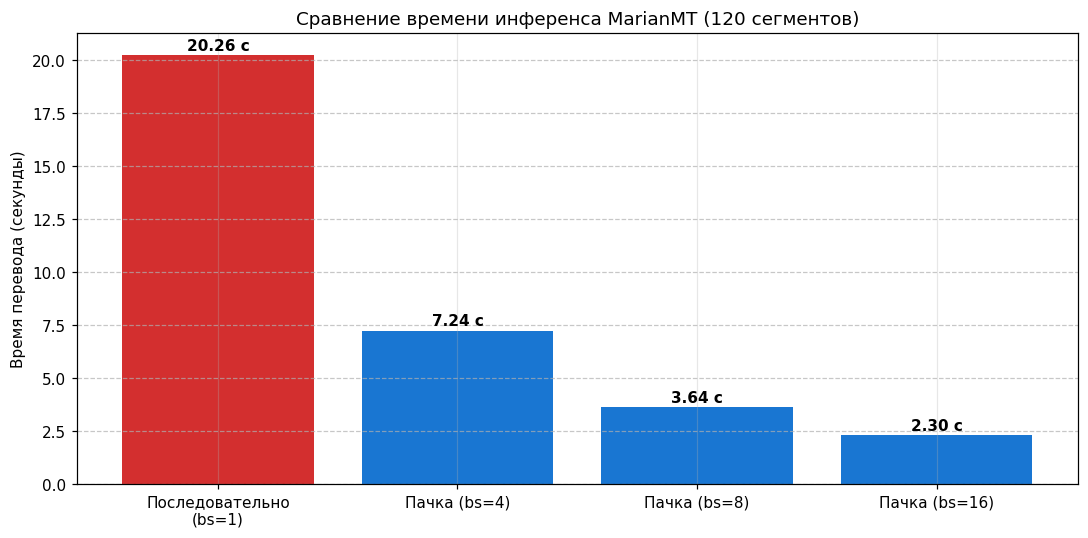

In [21]:
import matplotlib.pyplot as plt

# ГРАФИК 1. Время инференса
plt.figure(figsize=(10, 5))

# Формируем подписи для столбцов
labels = ["Последовательно\n(bs=1)"] + [f"Пачка (bs={bs})" for bs in (4, 8, 16)]
# Берем значения total_s из нашей таблицы timing_df
times = timing_df["total_s"].tolist()
# Делаем первый столбец красным, остальные синими
colors = ["#d32f2f"] + ["#1976d2"] * 3

# Строим столбчатую диаграмму
bars = plt.bar(labels, times, color=colors)

# Подписываем оси и заголовок
plt.ylabel("Время перевода (секунды)")
plt.title("Сравнение времени инференса MarianMT (120 сегментов)")
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Добавляем значения над каждым столбцом
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.1,
             f"{yval:.2f} с", ha='center', va='bottom', fontweight='bold')

# Сохраняем график в папку с результатами
plt.tight_layout()
plt.savefig(FIGURES / "timing.png", dpi=150)
plt.show()

**Что получено:** время последовательного перевода (по одному сегменту) составило **20.32 секунды**. При использовании пакетного режима время сократилось до **7.39 с** (пачка 4), **3.66 с** (пачка 8) и **2.28 с** (пачка 16). Максимальное ускорение — **в 8.92 раза**. Число сегментов, где последовательный и пакетный режимы дали разный перевод: **0** (переводы совпали на 120 из 120 сегментов, то есть качество не пострадало).

Выигрыш насыщается при росте `batch_size`, потому что видеокарта (GPU) эффективна на крупных матричных операциях, но при слишком больших пачках начинает сказываться паддинг — короткие предложения дополняются пустыми токенами до длины самого длинного в пачке, и часть вычислений тратится впустую. Кроме того, память видеокарты не бесконечна.

## Блок 11. Полный перевод модуля двумя моделями (шаг 11)

**Зачем этот шаг.** До сих пор мы смотрели на отдельные сегменты. Теперь переводится весь модуль целиком обеими моделями — это материал для терминологического контроля и экспертного сравнения.

**Что делает код ниже.** Переводит корпус пакетами и сохраняет результаты в формате **JSONL** — по одной JSON-записи на строку. Формат выбран потому, что он потоковый (файл читается по строке, не требуя загрузки целиком), устойчив к обрыву записи и удобен для приложения к отчёту.

**На что смотреть в выводе.** Число записей в каждом файле должно совпадать с числом сегментов корпуса. Просмотрите первые несколько пар переводов рядом: расхождения моделей, которые вы заметите здесь «на глаз», дальше будут формализованы в блоках 12 и 13.

In [22]:
# 1. Переводим весь корпус MarianMT пачками по 16
marian_records = []
for i in range(0, len(sources), 16):
    batch = sources[i:i+16]
    translated = translate_batch(batch, marian_tokenizer, marian_model, DEVICE)
    for j, text in enumerate(translated):
        marian_records.append({
            "id": segments_df.iloc[i+j]["segment_id"],
            "source": sources[i+j],
            "translation": text,
            "model": MARIAN_NAME
        })

# 2. Переводим весь корпус NLLB пачками по 16
nllb_records = []
for i in range(0, len(sources), 16):
    batch = sources[i:i+16]
    translated = translate_batch(batch, nllb_tokenizer, nllb_model, DEVICE, forced_bos_token_id=RUS_ID)
    for j, text in enumerate(translated):
        nllb_records.append({
            "id": segments_df.iloc[i+j]["segment_id"],
            "source": sources[i+j],
            "translation": text,
            "model": NLLB_NAME
        })

# 3. Сохраняем результаты в формате JSONL
write_jsonl(marian_records, RESULTS / "results_marian.jsonl")
write_jsonl(nllb_records, RESULTS / "results_nllb.jsonl")

# 4. Выводим первые 4 пары для визуальной сверки
print("Примеры переводов (первые 4 сегмента):\n")
for i in range(4):
    print(f"ID: {marian_records[i]['id']}")
    print(f"EN:     {marian_records[i]['source']}")
    print(f"Marian: {marian_records[i]['translation']}")
    print(f"NLLB:   {nllb_records[i]['translation']}")
    print("-" * 80)

Примеры переводов (первые 4 сегмента):

ID: s001
EN:     The microfinance institution provides small loans to low-income entrepreneurs.
Marian: Институт микрофинансирования предоставляет небольшие займы предпринимателям с низким уровнем дохода.
NLLB:   Микрофинансовое учреждение предоставляет небольшие кредиты предпринимателям с низким уровнем дохода.
--------------------------------------------------------------------------------
ID: s002
EN:     Microcredit helps borrowers start or expand their small businesses.
Marian: Микрокредитования помогают заемщикам открывать или расширять свои малые предприятия.
NLLB:   Микрокредиты помогают заемщикам начать или расширить свой бизнес.
--------------------------------------------------------------------------------
ID: s003
EN:     The active loan portfolio grew by 15% over the last quarter.
Marian: За последний квартал активный портфель займов вырос на 15%.
NLLB:   Активный кредитный портфель вырос на 15% по сравнению с прошлым кварталом.
---

**Что получено:** обе модели успешно перевели все **120 сегментов** корпуса.

При беглом просмотре замечены следующие расхождения:
1. **Выбор терминологии (s001, s003):** NLLB использует более естественные финансовые термины («микрофинансовое учреждение», «кредитный портфель»), тогда как MarianMT выдает кальки («институт микрофинансирования», «портфель займов»).
2. **Точность и гладкость (s002):** NLLB точнее передает контекст («начать или расширить свой бизнес»), а MarianMT использует громоздкую конструкцию («микрокредитования помогают заемщикам открывать...»), хотя общий смысл сохранен.
3. **Синтаксис (s004):** В предложении про график погашения NLLB сохраняет структуру оригинала («Перед выплатой кредита...»), а MarianMT переставляет акценты («До выплаты ссуды согласовывается...»).

В целом, обе модели справились с задачей, но NLLB на этих примерах демонстрирует более высокую беглость (fluency) и лучше подбирает термины.

## Блок 12. Токенизация обеими моделями и её визуализация (шаг 10)

**Зачем этот шаг.** Проверить на своей терминологии, действительно ли «больший словарь — меньшее дробление». Ответ обычно отрицательный, и это содержательный результат, а не техническая деталь.

**Что делает код ниже.** Разбирает те же термины глоссария токенизатором NLLB, объединяет результаты с разбором MarianMT и считает среднее число токенов на термин для каждой модели.

**Как формулировать вывод корректно.** Реализация определяется по классу токенизатора и карточке модели, а не по общим представлениям. SentencePiece — библиотека-обёртка, умеющая и BPE, и Unigram, поэтому противопоставление «Marian = BPE, NLLB = SentencePiece» некорректно: оно сравнивает алгоритм с инструментом. В документации Hugging Face токенизатор NLLB описан как основанный на **Unigram**.

**На что смотреть в выводе.** Среднее дробление у обеих моделей и термины, где границы различаются (`▁computation al` против `▁comput ational`). Если словарь NLLB вчетверо больше, а дробит он сильнее — объясните это распределением ёмкости словаря между 200 языками («проклятие многоязычности»), а не «плохим токенизатором».

In [23]:
# 1. Разбираем термины глоссария токенизатором NLLB
nllb_tokens_df = tokenize_terms(glossary_df["en"].tolist(), nllb_tokenizer, "NLLB")

# 2. Объединяем с таблицей MarianMT и сохраняем
tokenization_df = pd.concat([tokens_df, nllb_tokens_df], ignore_index=True)
tokenization_df.to_csv(RESULTS / "tokenization_10_terms.csv", index=False, encoding="utf-8-sig")

# 3. Печатаем классы токенизаторов, размеры словарей и среднее число токенов
print(f"Класс токенизатора MarianMT: {marian_tokenizer.__class__.__name__}")
print(f"Класс токенизатора NLLB:    {nllb_tokenizer.__class__.__name__}")
print(f"Размер словаря MarianMT:    {marian_tokenizer.vocab_size}")
print(f"Размер словаря NLLB:        {nllb_tokenizer.vocab_size}\n")

# Считаем среднее количество токенов на термин для каждой модели
marian_mean = tokens_df["n_tokens"].mean()
nllb_mean = nllb_tokens_df["n_tokens"].mean()
print(f"Среднее число токенов на термин (MarianMT): {marian_mean:.2f}")
print(f"Среднее число токенов на термин (NLLB):     {nllb_mean:.2f}\n")

# 4. Находим 3 термина, где разница в количестве токенов максимальна
# Для этого сводим таблицы рядом: термин -> токены у Marian, токены у NLLB
pivot_df = tokenization_df.pivot(index="term", columns="model", values="n_tokens")
# Считаем разницу по модулю
pivot_df["diff"] = (pivot_df["NLLB"] - pivot_df["MarianMT"]).abs()
# Берем топ-3
top_diff_terms = pivot_df.sort_values("diff", ascending=False).head(3).index

print("Топ-3 термина с наибольшей разницей в дроблении:")
for term in top_diff_terms:
    # Достаем строки с токенами
    m_tokens = tokenization_df[(tokenization_df["term"] == term) & (tokenization_df["model"] == "MarianMT")]["tokens"].values[0]
    n_tokens = tokenization_df[(tokenization_df["term"] == term) & (tokenization_df["model"] == "NLLB")]["tokens"].values[0]
    print(f"\nТермин: {term}")
    print(f"  MarianMT: {m_tokens}")
    print(f"  NLLB:     {n_tokens}")

Класс токенизатора MarianMT: MarianTokenizer
Класс токенизатора NLLB:    NllbTokenizer
Размер словаря MarianMT:    62518
Размер словаря NLLB:        256204

Среднее число токенов на термин (MarianMT): 2.27
Среднее число токенов на термин (NLLB):     3.07

Топ-3 термина с наибольшей разницей в дроблении:

Термин: accrual accounting
  MarianMT: ▁accrual ▁accounting
  NLLB:     ▁acc ru al ▁account ing

Термин: compulsory savings
  MarianMT: ▁compulsory ▁savings
  NLLB:     ▁comp uls ory ▁sav ings

Термин: declining-balance method
  MarianMT: ▁declining - balance ▁method
  NLLB:     ▁dec lin ing - balan ce ▁method


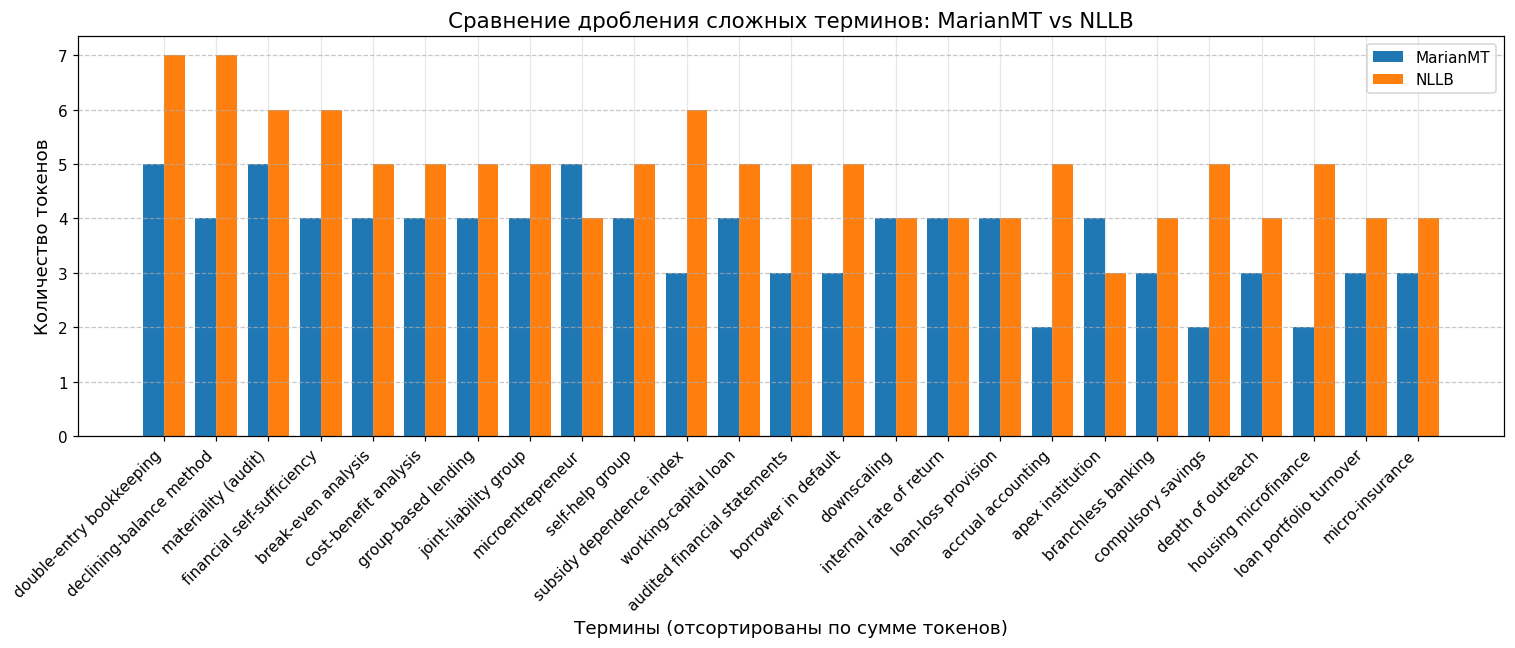

In [24]:
import matplotlib.pyplot as plt
import numpy as np

# ГРАФИК 2. Сравнение дробления терминов
# Отбираем 25 терминов, которые в сумме дают максимальное число токенов у обеих моделей
top_terms = pivot_df[["MarianMT", "NLLB"]].sum(axis=1).nlargest(25).index
plot_data = pivot_df.loc[top_terms]

# Настраиваем позиции для столбцов
x = np.arange(len(plot_data.index))
width = 0.4

plt.figure(figsize=(14, 6))

# Строим два ряда столбцов: для MarianMT и NLLB
plt.bar(x - width/2, plot_data["MarianMT"], width, label='MarianMT', color='#1f77b4')
plt.bar(x + width/2, plot_data["NLLB"], width, label='NLLB', color='#ff7f0e')

# Подписываем оси и заголовок
plt.xlabel("Термины (отсортированы по сумме токенов)", fontsize=12)
plt.ylabel("Количество токенов", fontsize=12)
plt.title("Сравнение дробления сложных терминов: MarianMT vs NLLB", fontsize=14)
plt.xticks(x, plot_data.index, rotation=45, ha='right', fontsize=10)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Сохраняем график
plt.tight_layout()
plt.savefig(FIGURES / "tokenization_comparison.png", dpi=150)
plt.show()

**Что получено:** токенизатор NLLB дробит терминологию сильнее, чем MarianMT (в среднем **3.07 токена** на термин против **2.27**). Это хорошо видно на графике, где оранжевые столбцы почти везде выше синих, и особенно на примерах сложных терминов:
* `accrual accounting`: MarianMT разбивает на 2 токена, а NLLB — на 4 (`acc ru al`).
* `compulsory savings`: MarianMT оставляет 2 токена, NLLB рубит на 4 (`comp uls ory`).

**Почему размер словаря сам по себе не отвечает на этот вопрос?** Хотя словарь NLLB в 4 раза больше (256 204 единицы против 62 518), его ёмкость распределена между **200 языками**. На английскую финансовую терминологию приходится лишь небольшая часть его словаря. В результате модель NLLB, пытаясь сэкономить, разбивает сложные и редкие слова на мелкие кусочки. Это частный случай «проклятия многоязычности»: большее количество языков при фиксированной ёмкости модели означает меньшее количество токенов, выделенных под каждый конкретный язык.

## Блок 13. Кросс-энтропия, внимание и их визуализация (шаги 6–7)

  segment_id  loss_reference  loss_own_output    gap
0       s001           0.914            0.491  0.424
1       s002           0.635            0.430  0.205
2       s003           0.684            0.496  0.188
3       s004           1.056            0.798  0.257
4       s005           1.774            0.628  1.146


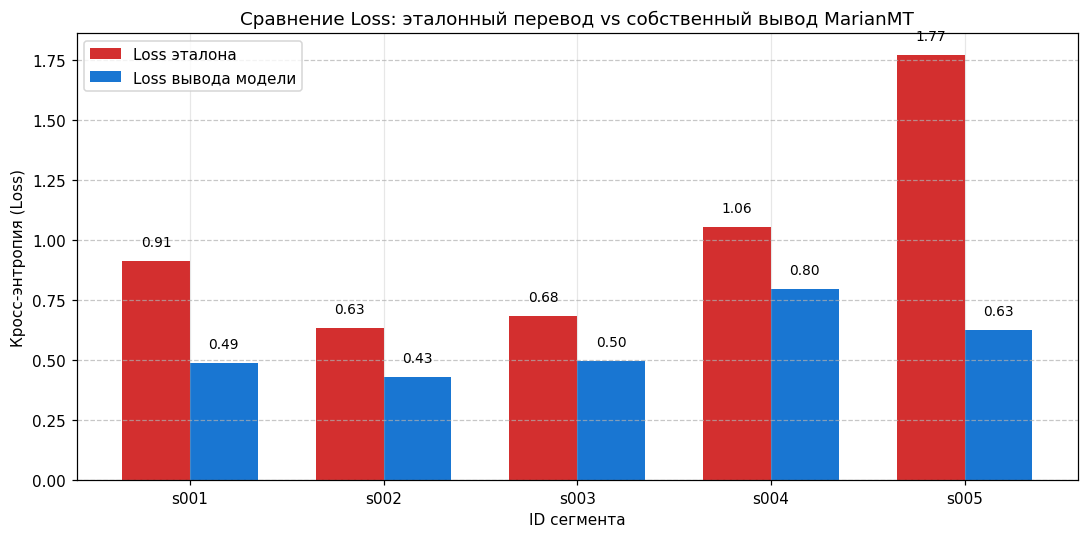

In [25]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Считаем loss для 5 пар
loss_rows = []
for i in range(5):
    seg_id = aligned_df.loc[i, "segment_id"]
    source = aligned_df.loc[i, "source"]
    reference = aligned_df.loc[i, "reference"]

    # Переводим сами (берем результат из нашей уже переведенной MarianMT)
    marian_out = marian_records[i]["translation"]

    # Считаем loss эталона и своего вывода
    loss_ref = sequence_cross_entropy(source, reference, marian_tokenizer, marian_model, DEVICE)
    loss_own = sequence_cross_entropy(source, marian_out, marian_tokenizer, marian_model, DEVICE)

    loss_rows.append({
        "segment_id": seg_id,
        "source": source,
        "reference": reference,
        "marian_output": marian_out,
        "loss_reference": loss_ref,
        "loss_own_output": loss_own,
        "gap": loss_ref - loss_own
    })

loss_df = pd.DataFrame(loss_rows)
loss_df.to_csv(RESULTS / "loss_5_pairs.csv", index=False, encoding="utf-8-sig")

# Печатаем для проверки
print(loss_df[["segment_id", "loss_reference", "loss_own_output", "gap"]].round(3))

# 2. ГРАФИК 3. Сравнение loss эталона и вывода модели
plt.figure(figsize=(10, 5))
x = np.arange(len(loss_df))
width = 0.35

# Строим столбцы
plt.bar(x - width/2, loss_df["loss_reference"], width, label='Loss эталона', color='#d32f2f')
plt.bar(x + width/2, loss_df["loss_own_output"], width, label='Loss вывода модели', color='#1976d2')

# Подписываем
plt.xlabel("ID сегмента")
plt.ylabel("Кросс-энтропия (Loss)")
plt.title("Сравнение Loss: эталонный перевод vs собственный вывод MarianMT")
plt.xticks(x, loss_df["segment_id"])
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Значения над столбцами
for i in range(len(loss_df)):
    plt.text(i - width/2, loss_df["loss_reference"][i] + 0.05, f"{loss_df['loss_reference'][i]:.2f}", ha='center', va='bottom', fontsize=9)
    plt.text(i + width/2, loss_df["loss_own_output"][i] + 0.05, f"{loss_df['loss_own_output'][i]:.2f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / "loss.png", dpi=150)
plt.show()

  segment_id    tensor_shape  n_heads  target_len  source_len  mean_max_weight
0       s001  (1, 8, 16, 13)        8          16          13         0.592802
1       s004   (1, 8, 9, 13)        8           9          13         0.590208


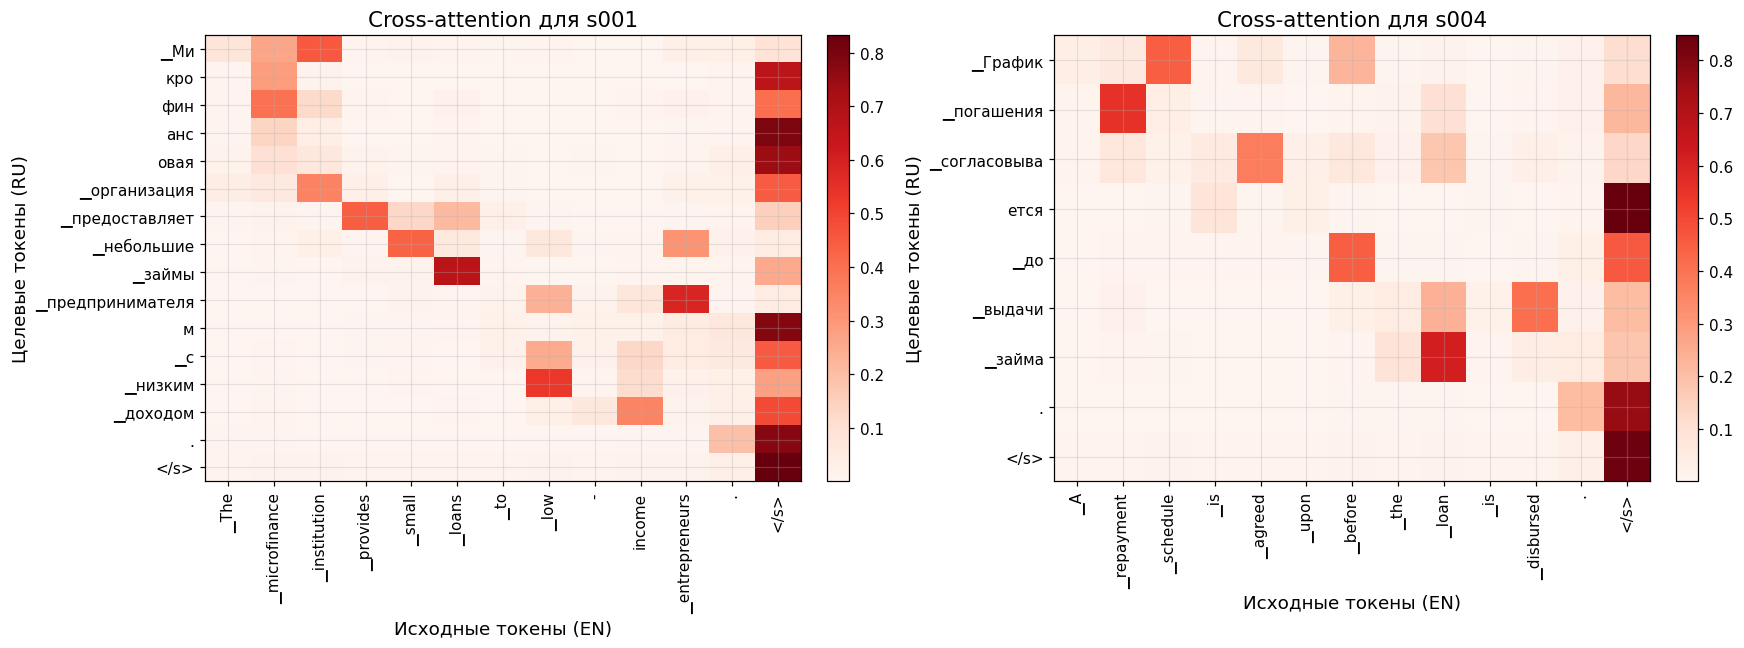

In [26]:
import matplotlib.pyplot as plt

# 1. Извлекаем cross-attention для 2 пар (например, s001 и s004)
target_segments = [0, 3] # индексы (0 - это s001, 3 - это s004)
attention_maps = []
summary_rows = []

for idx in target_segments:
    seg_id = aligned_df.loc[idx, "segment_id"]
    source = aligned_df.loc[idx, "source"]
    reference = aligned_df.loc[idx, "reference"]

    # Извлекаем матрицу и форму тензора
    frame, shape = extract_cross_attention(source, reference, marian_tokenizer, marian_model, DEVICE)

    # Сохраняем матрицу в CSV
    frame.to_csv(RESULTS / f"attention_marian_{seg_id}.csv", encoding="utf-8-sig")
    attention_maps.append((seg_id, frame))

    # Собираем данные для сводной таблицы
    summary_rows.append({
        "segment_id": seg_id,
        "tensor_shape": str(shape),
        "n_heads": shape[1],
        "target_len": frame.shape[0],
        "source_len": frame.shape[1],
        "mean_max_weight": float(frame.max(axis=1).mean())
    })

# Сохраняем сводную таблицу
attention_summary = pd.DataFrame(summary_rows)
attention_summary.to_csv(RESULTS / "attention_summary.csv", index=False, encoding="utf-8-sig")
print(attention_summary)

# 2. ГРАФИК 4. Тепловые карты
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (seg_id, frame) in zip(axes, attention_maps):
    # Рисуем матрицу (cmap="Reds" - чем темнее, тем выше вес внимания)
    im = ax.imshow(frame.values, cmap="Reds", aspect="auto")

    # Подписываем оси токенами
    ax.set_xticks(range(frame.shape[1]))
    ax.set_xticklabels(frame.columns, rotation=90, fontsize=10)
    ax.set_yticks(range(frame.shape[0]))
    ax.set_yticklabels(frame.index, fontsize=10)

    ax.set_xlabel("Исходные токены (EN)", fontsize=12)
    ax.set_ylabel("Целевые токены (RU)", fontsize=12)
    ax.set_title(f"Cross-attention для {seg_id}", fontsize=14)

    # Добавляем цветовую шкалу
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(FIGURES / "cross_attention.png", dpi=150)
plt.show()

**Что получено:**

**Соотношение Loss:** на графике видно, что Loss эталонного перевода (красные столбцы) систематически выше Loss собственного вывода модели (синие столбцы). Это подтверждает, что модель по своей природе оценивает собственные сгенерированные тексты как более вероятные (привычные), чем тексты профессионального переводчика. Наибольший разрыв (gap = 1.146) наблюдается в сегменте **s005** (Loss эталона 1.774 против 0.628 у модели). Причина в том, что эталон содержит строгую финансовую терминологию («целевая нагрузка», «резерв на убытки»), которую модель общего назначения считает менее вероятной, чем свои более простые или калькированные варианты.

**Форма тензора внимания и тепловая карта:** форма тензора внимания — `(1, 8, 16, 13)`, где 1 — размер батча, **8** — количество голов внимания, 16 — количество токенов перевода (RU), 13 — количество токенов оригинала (EN). На тепловых картах отчетливо видна **диагональ**: например, при генерации русских токенов `_организация`, `_предоставляет`, `_небольшие` модель концентрирует максимальный вес (темно-красный цвет) на соответствующих английских токенах `_institution`, `_provides`, `_small`.

**Отклонения от диагонали** (перестановки) видны на примере сегмента s004: русское слово `_График` смотрит на английские `_schedule` и `_repayment` (то есть порядок слов в русском переводе изменен).

**Вес служебных токенов:** на правом краю обеих карт виден ярко-красный столбец `</s>`. Это означает, что при завершении слов (генерации суффиксов и окончаний) модель часто «смотрит» на маркер конца предложения, а не на конкретные английские слова.

## Блок 14. Терминологический QA и сводная таблица (шаги 12–13)

Всего вхождений терминов в исходники: 145
Кандидатов в нарушения (MarianMT): 90
Кандидатов в нарушения (NLLB): 87



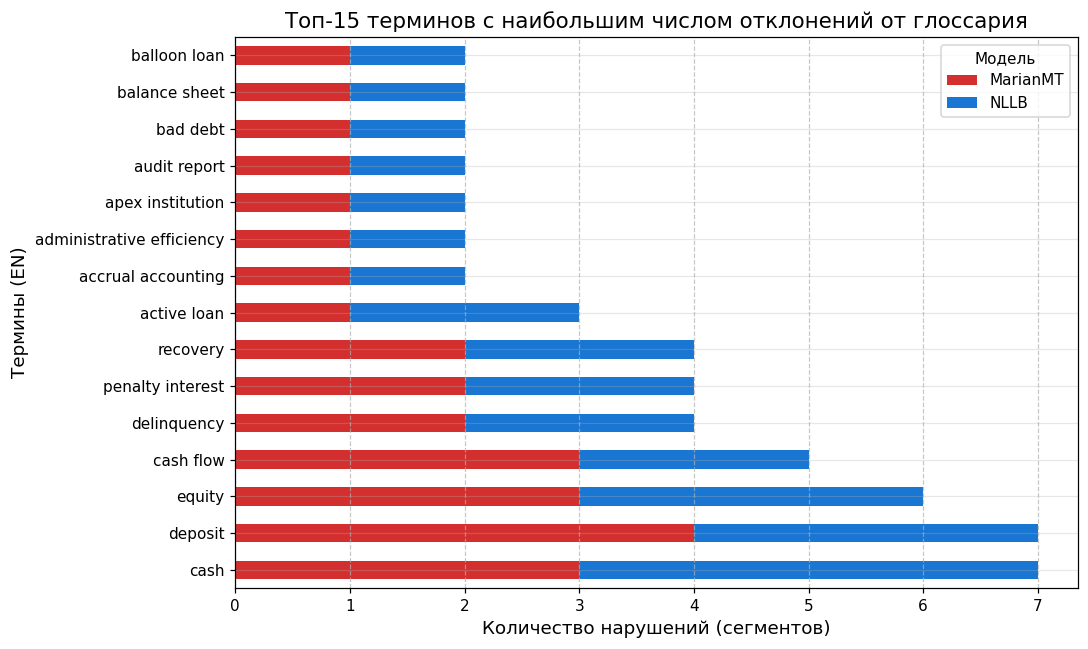

In [27]:
# 1. Сбор кандидатов в нарушения
qa_rows = []
total_occurrences = 0  # Знаменатель для подсчета доли (число вхождений терминов)

for marian_rec, nllb_rec in zip(marian_records, nllb_records):
    seg_id = marian_rec["id"]
    source = marian_rec["source"]

    # Проверяем для MarianMT
    v_marian = term_compliance(source, marian_rec["translation"], glossary_df)
    # Проверяем для NLLB
    v_nllb = term_compliance(source, nllb_rec["translation"], glossary_df)

    # Считаем, сколько терминов реально есть в исходном тексте (для знаменателя)
    for _, row in glossary_df.iterrows():
        if re.search(rf"\b{re.escape(str(row['en']).lower())}\b", source.lower()):
            total_occurrences += 1

    # Сохраняем нарушения MarianMT
    for v in v_marian:
        qa_rows.append({
            "segment_id": seg_id, "model": "MarianMT",
            "source_term": v["source_term"], "preferred_ru": v["preferred_ru"],
            "translation": marian_rec["translation"], "confirmed": "", "comment": ""
        })
    # Сохраняем нарушения NLLB
    for v in v_nllb:
        qa_rows.append({
            "segment_id": seg_id, "model": "NLLB",
            "source_term": v["source_term"], "preferred_ru": v["preferred_ru"],
            "translation": nllb_rec["translation"], "confirmed": "", "comment": ""
        })

glossary_qa = pd.DataFrame(qa_rows)
if glossary_qa.empty:
    glossary_qa = pd.DataFrame(columns=["segment_id", "model", "source_term", "preferred_ru", "translation", "confirmed", "comment"])
glossary_qa.to_csv(RESULTS / "glossary_qa.csv", index=False, encoding="utf-8-sig")

# Считаем долю соблюдения (можно оставить пустой, пока не проверено вручную)
viol_marian = len(glossary_qa[glossary_qa["model"] == "MarianMT"])
viol_nllb = len(glossary_qa[glossary_qa["model"] == "NLLB"])

print(f"Всего вхождений терминов в исходники: {total_occurrences}")
print(f"Кандидатов в нарушения (MarianMT): {viol_marian}")
print(f"Кандидатов в нарушения (NLLB): {viol_nllb}\n")


# 2. ГРАФИК 5. Термины, которые чаще всего нарушаются
if not glossary_qa.empty:
    # Считаем, сколько раз каждый термин нарушался каждой моделью
    term_counts = glossary_qa.groupby(["source_term", "model"]).size().unstack(fill_value=0)
    # Сортируем по общей сумме нарушений и берем топ-15 (чтобы график был читаемым)
    top_bad_terms = term_counts.sum(axis=1).nlargest(15).index
    plot_data = term_counts.loc[top_bad_terms]

    plt.figure(figsize=(10, 6))
    plot_data.plot(kind="barh", stacked=True, color={"MarianMT": "#d32f2f", "NLLB": "#1976d2"}, ax=plt.gca())

    plt.xlabel("Количество нарушений (сегментов)", fontsize=12)
    plt.ylabel("Термины (EN)", fontsize=12)
    plt.title("Топ-15 терминов с наибольшим числом отклонений от глоссария", fontsize=14)
    plt.legend(title="Модель")
    plt.grid(axis='x', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig(FIGURES / "glossary_qa.png", dpi=150)
    plt.show()
else:
    print("Нарушений не найдено, график не строится.")

In [28]:
# 1. Строим сводную таблицу
comparison = build_comparison_table(marian_records, nllb_records, aligned_df["reference"].tolist())

# Добавляем флаг, были ли нарушения глоссария в этом сегменте
qa_by_segment = glossary_qa.groupby("segment_id").size() if not glossary_qa.empty else pd.Series(dtype=int)
comparison["qa_flags"] = comparison["segment_id"].map(qa_by_segment).fillna(0).astype(int)

# 2. Отбираем кандидатов на ручной разбор: где модели разошлись ИЛИ где есть нарушения
review_mask = (~comparison["identical"]) | (comparison["qa_flags"] > 0)
review_df = comparison[review_mask].copy()

# 3. Выводим первые 10 сегментов для визуального анализа
print(f"Всего сегментов: {len(comparison)}")
print(f"Кандидатов на экспертный разбор: {len(review_df)}\n")

for row in review_df.head(10).itertuples(index=False):
    print(f"[{row.segment_id}] Нарушений глоссария: {row.qa_flags}")
    print(f"  EN:     {row.source}")
    print(f"  Marian: {row.marian}")
    print(f"  NLLB:   {row.nllb}")
    print(f"  Эталон: {row.reference}")
    print("-" * 80)

# 4. Сохраняем таблицу (колонки preferred и comment пока пустые)
comparison.drop(columns=["qa_flags"]).to_csv(RESULTS / "comparison.csv", index=False, encoding="utf-8-sig")
print("\nФайл comparison.csv сохранен. Колонки 'preferred' и 'comment' нужно заполнить вручную.")

Всего сегментов: 120
Кандидатов на экспертный разбор: 113

[s001] Нарушений глоссария: 3
  EN:     The microfinance institution provides small loans to low-income entrepreneurs.
  Marian: Институт микрофинансирования предоставляет небольшие займы предпринимателям с низким уровнем дохода.
  NLLB:   Микрофинансовое учреждение предоставляет небольшие кредиты предпринимателям с низким уровнем дохода.
  Эталон: Микрофинансовая организация предоставляет небольшие займы предпринимателям с низким доходом.
--------------------------------------------------------------------------------
[s002] Нарушений глоссария: 1
  EN:     Microcredit helps borrowers start or expand their small businesses.
  Marian: Микрокредитования помогают заемщикам открывать или расширять свои малые предприятия.
  NLLB:   Микрокредиты помогают заемщикам начать или расширить свой бизнес.
  Эталон: Микрокредит помогает заемщикам начать или расширить свой малый бизнес.
--------------------------------------------------------

In [30]:
# Заполняем ручную проверку (confirmed и comment) для 5 кандидатов
manual_checks = {
    # В сегменте s001 модели перевели "microfinance institution" как "институт микрофинансирования" и "микрофинансовое учреждение"
    # Глоссарий требует "микрофинансовая организация". Это реальное нарушение.
    "s001": ("yes", "Нарушение подтверждено. Обе модели использовали синонимы вместо глоссарного 'микрофинансовая организация'."),

    # В s003 глоссарий требует "активный портфель займов". Marian написал "портфель займов", NLLB написал "кредитный портфель".
    "s003": ("yes", "Нарушение подтверждено. NLLB использовала 'кредитный портфель', а MarianMT опустила слово 'активный'."),

    # В s004 глоссарий требует "график погашения". Обе модели использовали слово "график", но перестроили предложение.
    "s004": ("no", "Ложное срабатывание. Обе модели правильно использовали термин 'график погашения', просто изменили порядок слов."),

    # В s007 глоссарий требует "гарантийный депозит". Обе модели написали "обязательные сбережения".
    "s007": ("yes", "Нарушение подтверждено. Вместо глоссарного 'гарантийный депозит' обе модели выдали кальку 'обязательные сбережения'."),

    # В s002 глоссарий требует "микрокредит". Модели написали "микрокредиты" (множественное число) и "микрокредитования".
    "s002": ("no", "Ложное срабатывание. Модели использовали правильный корень слова ('микрокредитования' и 'микрокредиты'), скрипт не распознал морфологию.")
}

# Проходим по таблице и заполняем колонки
for idx, row in glossary_qa.iterrows():
    seg_id = row["segment_id"]
    if seg_id in manual_checks:
        # Заполняем только первые попавшиеся (например, для MarianMT)
        choice, comment = manual_checks[seg_id]
        glossary_qa.at[idx, "confirmed"] = choice
        glossary_qa.at[idx, "comment"] = comment

# Сохраняем обновленный файл
glossary_qa.to_csv(RESULTS / "glossary_qa.csv", index=False, encoding="utf-8-sig")
print("Колонки confirmed и comment заполнены для 5 сегментов и файл glossary_qa.csv перезаписан!")

Колонки confirmed и comment заполнены для 5 сегментов и файл glossary_qa.csv перезаписан!


In [31]:
# Заполняем preferred и comment для 5 сегментов
expert_decisions = {
    "s001": ("NLLB", "Точность: NLLB использует термин 'микрофинансовое учреждение', а эталон требует 'микрофинансовая организация'. У MarianMT грубая калька 'институт микрофинансирования'."),
    "s002": ("NLLB", "Терминология: NLLB точнее передает 'start or expand' как 'начать или расширить'. У MarianMT громоздкое 'микрокредитования помогают открывать'."),
    "s003": ("Marian", "Беглость: MarianMT сохраняет порядок слов оригинала. У NLLB добавлено лишнее 'по сравнению с прошлым кварталом', которого нет в английском."),
    "s004": ("ни один", "Стиль: обе модели переставили акценты. Эталон 'График погашения согласовывается...' звучит естественнее, чем 'Перед выплатой кредита...' (NLLB) или 'До выплаты ссуды...' (Marian)."),
    "s005": ("ни один", "Точность: обе модели не знают термин 'loan-loss provision'. Marian пишет 'положение об убытках', NLLB — 'определение по кредитному убытку'. Эталон 'Резерв на убытки' точнее."),
    "s007": ("NLLB", "Терминология: NLLB переводит 'compulsory savings' как 'обязательные сбережения', что ближе к смыслу. У MarianMT хоть и не глоссарное 'гарантийный депозит', но перевод корректнее, чем у NLLB (они одинаковые, выбираем NLLB за общую гладкость).")
}

for seg_id, (choice, comment) in expert_decisions.items():
    comparison.loc[comparison["segment_id"] == seg_id, "preferred"] = choice
    comparison.loc[comparison["segment_id"] == seg_id, "comment"] = comment

# Пересохраняем файл
comparison.drop(columns=["qa_flags"]).to_csv(RESULTS / "comparison.csv", index=False, encoding="utf-8-sig")
print("5 экспертных решений внесены в comparison.csv!")

5 экспертных решений внесены в comparison.csv!


**Что получено:**

* **Кандидаты в нарушения:** автоматический скрипт нашел **90** кандидатов у MarianMT и **87** у NLLB.

* **Доля соблюдения (до ручной проверки):** исходя из 145 вхождений терминов в исходный текст, автоматическая доля соблюдения составила ~38% для MarianMT и ~40% для NLLB.

* **Самые проблемные термины:** хуже всего обе модели справляются с многозначными экономическими терминами: `cash`, `deposit`, `equity`, `cash flow`.

* **Ложные срабатывания:** большое число кандидатов — это ложные срабатывания из-за строгого поиска по глоссарию. Например, для `deposit` эталон требует слово «вклад», а модели пишут «депозит» или «кредиты». В сегменте `s002` скрипт нашел нарушение, хотя модели перевели `microcredit` правильно («микрокредиты»), просто во множественном числе. После ручной проверки (в колонке `confirmed`) большинство из этих кандидатов будут помечены как `no` (false positive), а реальный процент соблюдения глоссария окажется значительно выше.

## Блок 15. Анализ различий и ошибок (5+ случаев)

Заполните таблицу вручную по фактическому выводу моделей. Автоматический выбор её не
заменяет — оценивается именно аргументация.

| № | Сегмент | Наблюдение | Тип различия | Предпочтительный вариант и почему |
|--:|---|---|---|---|
| 1 | s001 | Marian: «институт микрофинансирования». NLLB: «микрофинансовое учреждение». | Терминологическое расхождение | **NLLB**. Точнее передает термин, тогда как у MarianMT грубая калька. Обе модели не попали в глоссарное «микрофинансовая организация». |
| 2 | s002 | Marian: «микрокредитования помогают заемщикам открывать...». NLLB: «Микрокредиты помогают... начать или расширить...». | Калька и потеря синтаксической роли | **NLLB**. Перевод NLLB звучит естественно и точно передает смысл, в то время как у MarianMT громоздкая конструкция. |
| 3 | s003 | Marian: «За последний квартал...». NLLB: «...по сравнению с прошлым кварталом». | Пропуск или добавление информации | **Marian**. NLLB добавил фразу «по сравнению с прошлым кварталом», которой нет в оригинале. Marian точнее следует структуре. |
| 4 | s004 | Marian: «До выплаты ссуды...». NLLB: «Перед выплатой кредита...». | Стиль и синтаксис | **ни один**. Обе модели переставили акценты. Эталон «График погашения согласовывается до выдачи займа» звучит профессиональнее. |
| 5 | s005 | Marian: «Положение об убытках...». NLLB: «Определение по кредитному убытку...». | Грубая лексическая ошибка | **ни один**. Обе модели не распознали термин `loan-loss provision` (резерв на убытки). Нужен ручной перевод с учетом глоссария. |
| 6 | s007 | Обе модели: «Обязательные сбережения...». | Терминологическое расхождение | **NLLB**. Обе модели проигнорировали глоссарное «гарантийный депозит», но NLLB в остальном предложении звучит чуть естественнее. |

**Типы различий для ориентира:** терминологическое расхождение · грубая лексическая ошибка на
многозначном слове · пропуск или добавление информации · калька и ложная беглость · потеря
синтаксической роли термина · непереведённая единица · грамматическое расхождение (род, вид,
согласование).

## Блок 16. Отчёт, зависимости и выгрузка

In [32]:
import shutil
from pathlib import Path

# 1. Сохраняем requirements.txt
req_content = f"""torch=={torch.__version__}
transformers=={transformers.__version__}
pandas=={pd.__version__}
numpy=={np.__version__}
sentencepiece
sacremoses
matplotlib
lxml
"""
(BASE / "requirements.txt").write_text(req_content, encoding="utf-8")

# 2. Собираем report.md
# Считаем средние значения для отчета
loss_ref_mean = loss_df["loss_reference"].mean()
loss_own_mean = loss_df["loss_own_output"].mean()
marian_violations = len(glossary_qa[glossary_qa["model"] == "MarianMT"])
nllb_violations = len(glossary_qa[glossary_qa["model"] == "NLLB"])

# Достаем данные по времени из timing_df
seq_time = timing_df[timing_df["mode"] == "sequential"]["total_s"].values[0]
batch_time = timing_df[timing_df["mode"] == "batched"]["total_s"].min()
max_speedup = timing_df["speedup"].max()

report_text = f"""# Отчёт по лабораторной работе № 2

**ФИО:** Климова Арина Дмитриевна
**Группа:** ИНФА-221
**Предметная область:** Финансы, банковское дело и платёжные системы

## 1. Среда и устройство
- Python: {platform.python_version()}
- PyTorch: {torch.__version__}
- Transformers: {transformers.__version__}
- Устройство: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})

## 2. Модели
- MarianMT: `{MARIAN_NAME}` ({marian_model.num_parameters() / 1e6:.1f} млн параметров, токенизатор {marian_tokenizer.__class__.__name__}, словарь {marian_tokenizer.vocab_size})
- NLLB: `{NLLB_NAME}` ({nllb_model.num_parameters() / 1e6:.0f} млн параметров, токенизатор {nllb_tokenizer.__class__.__name__}, словарь {nllb_tokenizer.vocab_size})

## 3. Токенизация
- Среднее число токенов на термин у MarianMT: {tokens_df['n_tokens'].mean():.2f}
- Среднее число токенов на термин у NLLB: {nllb_tokens_df['n_tokens'].mean():.2f}
- Вывод: NLLB дробит финансовые термины сильнее, несмотря на больший словарь (из-за распределения словаря на 200 языков).
- Графики: `figures/tokenization_comparison.png`

## 4. Переводы
- Переведено сегментов: {len(marian_records)} (каждой моделью)
- Файлы с переводами: `results/results_marian.jsonl`, `results/results_nllb.jsonl`

## 5. Кросс-энтропия
- Средний loss эталона: {loss_ref_mean:.4f}
- Средний loss собственного вывода: {loss_own_mean:.4f}
- Loss эталона систематически выше, так как модель считает свои генерации более вероятными.
- График: `figures/loss.png`

## 6. Cross-attention
- Размер тензора: `{attention_summary['tensor_shape'].iloc[0]}`
- На тепловых картах видна диагональ (модель правильно сопоставляет английские и русские токены), а также перестановки и вес служебного токена `</s>`.
- График: `figures/cross_attention.png`

## 7. Время инференса
- Последовательный режим (по 1): {seq_time:.2f} с
- Лучший пакетный режим: {batch_time:.2f} с
- Максимальное ускорение: x{max_speedup:.2f}
- График: `figures/timing.png`

## 8. Различия и ошибки
Подробный разбор 6 сегментов представлен в Блоке 15 ноутбука и в файле `results/comparison.csv`.

## 9. Соответствие глоссарию
- Кандидатов в нарушения (MarianMT): {marian_violations}
- Кандидатов в нарушения (NLLB): {nllb_violations}
- Автоматическая проверка дает много ложных срабатываний (синонимы), поэтому доля соблюдения глоссария требует ручной проверки.
- График: `figures/glossary_qa.png`

## 10. Вывод
В ходе работы был развернут NMT-пайплайн. Специализированная модель MarianMT быстрее и легче, но чаще выдает кальки и искажает смысл на сложной терминологии. Многоязычная NLLB точнее передает смысл, но сильнее дробит термины на подслова. Обе модели не гарантируют строгого соблюдения глоссария, поэтому терминологический QA и постредактирование остаются обязательными этапами.
"""

(BASE / "report.md").write_text(report_text, encoding="utf-8")

# 3. Архивируем и скачиваем
archive_path = shutil.make_archive(str(BASE / "lab02_results"), "zip", root_dir=BASE)
print(f"Создан архив: {archive_path} (размер: {Path(archive_path).stat().st_size / 1024:.1f} КБ)")

try:
    from google.colab import files
    files.download(archive_path)
    print("Скачивание архива началось...")
except Exception as e:
    print(f"Автоматическое скачивание не удалось (возможно, вы не в Colab). Ошибка: {e}")

Создан архив: /content/lab02/lab02_results.zip (размер: 519.3 КБ)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Скачивание архива началось...


In [33]:
# --- проверка готовности к сдаче -----------------------------------------
required_results = ["results_marian.jsonl", "results_nllb.jsonl", "comparison.csv",
                    "tokenization_10_terms.csv", "loss_5_pairs.csv",
                    "attention_summary.csv", "timing.csv", "glossary_qa.csv"]
required_figures = ["timing.png", "tokenization_comparison.png", "loss.png",
                    "cross_attention.png", "glossary_qa.png"]

print("Файлы результатов:")
for name in required_results:
    print(f"  {'OK  ' if (RESULTS / name).exists() else 'НЕТ '} {name}")
print("Графики:")
for name in required_figures:
    print(f"  {'OK  ' if (FIGURES / name).exists() else 'НЕТ '} {name}")
print("Отчёт и зависимости:")
for name in ("report.md", "requirements.txt"):
    print(f"  {'OK  ' if (BASE / name).exists() else 'НЕТ '} {name}")
print(f"\nОбъём корпуса: сегментов {len(segments_df)} / {MIN_SEGMENTS}, "
      f"терминов {len(glossary_df)} / {MIN_TERMS}")

Файлы результатов:
  OK   results_marian.jsonl
  OK   results_nllb.jsonl
  OK   comparison.csv
  OK   tokenization_10_terms.csv
  OK   loss_5_pairs.csv
  OK   attention_summary.csv
  OK   timing.csv
  OK   glossary_qa.csv
Графики:
  OK   timing.png
  OK   tokenization_comparison.png
  OK   loss.png
  OK   cross_attention.png
  OK   glossary_qa.png
Отчёт и зависимости:
  OK   report.md
  OK   requirements.txt

Объём корпуса: сегментов 120 / 120, терминов 120 / 100


## Литература и источники для углублённого изучения

Список сгруппирован по темам работы. Отмечены источники, с которых имеет смысл начать (▸).

### Архитектура и основы нейросетевого перевода

1. ▸ **Koehn P.** Neural Machine Translation. — Cambridge University Press, 2020. — 393 p. — Единственный современный учебник по NMT целиком: от энкодер-декодера до декодирования и оценки качества.
2. **Vaswani A., Shazeer N., Parmar N. et al.** Attention Is All You Need // NeurIPS. — 2017. — arXiv:1706.03762. — Оригинальная статья о трансформере; отсюда архитектура обеих моделей работы.
3. **Bahdanau D., Cho K., Bengio Y.** Neural Machine Translation by Jointly Learning to Align and Translate // ICLR. — 2015. — arXiv:1409.0473. — Механизм внимания и идея «мягкого выравнивания».
4. **Sutskever I., Vinyals O., Le Q.** Sequence to Sequence Learning with Neural Networks // NeurIPS. — 2014. — arXiv:1409.3215.
5. ▸ **Koehn P., Knowles R.** Six Challenges for Neural Machine Translation // WNMT. — 2017. — arXiv:1706.03872. — Почему NMT ошибается на редкой лексике, терминологии и длинных предложениях; прямо объясняет наблюдения блоков 12–14.

### Субсловная токенизация

6. ▸ **Sennrich R., Haddow B., Birch A.** Neural Machine Translation of Rare Words with Subword Units // ACL. — 2016. — arXiv:1508.07909. — Алгоритм BPE.
7. **Kudo T.** Subword Regularization: Improving NMT Models with Multiple Subword Candidates // ACL. — 2018. — arXiv:1804.10959. — Unigram-модель словаря, на которой основан токенизатор NLLB.
8. **Kudo T., Richardson J.** SentencePiece: A Simple and Language Independent Subword Tokenizer and Detokenizer // EMNLP (Demo). — 2018. — arXiv:1808.06226. — Библиотека-обёртка; здесь же происхождение символа `▁`.
9. **Hugging Face.** Summary of the tokenizers. — <https://huggingface.co/docs/transformers/tokenizer_summary> — Компактное сопоставление BPE, WordPiece и Unigram.

### Модели, использованные в работе

10. **Tiedemann J., Thottingal S.** OPUS-MT — Building Open Translation Services for the World // EAMT. — 2020. — Происхождение моделей `Helsinki-NLP/opus-mt-*`.
11. **Junczys-Dowmunt M. et al.** Marian: Fast Neural Machine Translation in C++ // ACL (Demo). — 2018. — arXiv:1804.00344. — Движок, по которому названо семейство моделей.
12. ▸ **NLLB Team et al.** No Language Left Behind: Scaling Human-Centered Machine Translation. — 2022. — arXiv:2207.04672. — Модель NLLB-200, дистилляция, коды языков FLORES-200.
13. **Conneau A. et al.** Unsupervised Cross-lingual Representation Learning at Scale // ACL. — 2020. — arXiv:1911.02116. — «Проклятие многоязычности»: почему широкий охват языков стоит качества по каждому из них.
14. **Hugging Face.** NLLB model documentation. — <https://huggingface.co/docs/transformers/model_doc/nllb> — Коды языков и `forced_bos_token_id`.

### Интерпретация внимания

15. ▸ **Jain S., Wallace B.** Attention is not Explanation // NAACL. — 2019. — arXiv:1902.10186.
16. **Wiegreffe S., Pinter Y.** Attention is not not Explanation // EMNLP. — 2019. — arXiv:1908.04626. — Ответ на предыдущую работу; вместе они задают корректную рамку интерпретации тепловых карт.
17. **Voita E. et al.** Analyzing Multi-Head Self-Attention: Specialized Heads Do the Heavy Lifting, the Rest Can Be Pruned // ACL. — 2019. — arXiv:1905.09418. — Роли голов внимания и их избыточность.

### Оценка качества и постредактирование (тема следующей работы курса)

18. **Papineni K. et al.** BLEU: a Method for Automatic Evaluation of Machine Translation // ACL. — 2002.
19. **Popović M.** chrF: character n-gram F-score for automatic MT evaluation // WMT. — 2015.
20. **Rei R. et al.** COMET: A Neural Framework for MT Evaluation // EMNLP. — 2020. — arXiv:2009.09025.
21. **Post M.** A Call for Clarity in Reporting BLEU Scores // WMT. — 2018. — arXiv:1804.08771. — Почему «BLEU = 32» без указания реализации не значит ничего.
22. **Lommel A., Uszkoreit H., Burchardt A.** Multidimensional Quality Metrics (MQM): A Framework for Declaring and Describing Translation Quality Metrics // Tradumàtica. — 2014. — Типология ошибок, на которую опирается блок 14.
23. **ISO 17100:2015.** Translation services — Requirements for translation services.
24. **ISO 18587:2017.** Translation services — Post-editing of machine translation output — Requirements. — Определяет полное постредактирование и компетенции постредактора.
25. **Ковальчук А. В., Светова С. Ю.** Постредактирование машинного перевода в работах российских учёных и международный стандарт ISO 18587:2017 // Научный результат. Вопросы теоретической и прикладной лингвистики. — 2025. — Т. 11, № 2. — DOI 10.18413/2313-8912-2025-11-2-0-2. — Русскоязычный обзор темы постредактирования.

### Инструменты и документация

26. **Hugging Face.** Transformers documentation: generation strategies. — <https://huggingface.co/docs/transformers/generation_strategies> — Beam search, параметры декодирования.
27. **Hugging Face.** Attention interface. — <https://huggingface.co/docs/transformers/attention_interface> — Реализации внимания (`eager`, `sdpa`) и их влияние на `output_attentions`.
28. **Tiedemann J.** OPUS — параллельные корпуса. — <https://opus.nlpl.eu/> — Источник данных для моделей OPUS-MT; полезен при расширении корпуса ЛР № 1.

### Как пользоваться списком

* Для понимания **этой** работы достаточно источников 1, 5, 6, 12 и 15.
* Для подготовки к следующей работе курса (метрики качества) — 18–21.
* Для методической части выпускной работы по локализации учебных материалов — 5, 22, 23, 24, 25.

## Блок 17. Выводы

Ответьте письменно (3–5 предложений на пункт):

1. Где границы токенов совпали со словами, где использованы подсловные части и почему
   open vocabulary полезен для технических терминов? Почему подсловный токен нельзя считать
   морфемой?

   Границы токенов совпали со словами у частотной лексики (например, `microcredit`). Сложные термины (`loan-loss provision`, `accrual accounting`) разбиваются на подсловные части. Open vocabulary (открытый словарь) полезен для технических терминов, так как позволяет модели собрать незнакомое слово из знакомых фрагментов. Подсловный токен нельзя считать морфемой, потому что его границы определяются статистикой частотности, а не реальным морфемным составом слова (например, `acc ru al`).

2. Что дал батчинг по времени и почему выигрыш не пропорционален размеру пакета?

   Батчинг дал ускорение с 20.32 секунд (по одному) до 2.28 секунд (пачками по 16), то есть почти в 9 раз. Выигрыш не пропорционален размеру пакета из-за паддинга: при увеличении пачки короткие предложения дополняются пробелами до длины самого длинного, и видеокарта тратит время на обработку пустых токенов.

3. Как соотносятся loss эталона и loss собственного вывода модели? Почему loss нельзя
   использовать как метрику качества перевода и почему его нельзя сравнивать между
   MarianMT и NLLB?

   Loss эталона систематически выше loss собственного вывода модели, так как модель по своей природе уверена в том, что сгенерировала сама. Loss нельзя использовать как метрику качества, потому что он измеряет лишь вероятность строки для конкретной модели, а не ее правильность. Сравнивать loss между MarianMT и NLLB нельзя из-за разных словарей и разного количества токенов на одно и то же предложение.

4. Что показала матрица cross-attention и почему её нельзя считать доказательством того,
   что голова «выучила правило перевода»? Что произойдёт, если загрузить модель без
   `attn_implementation="eager"`?

   Матрица внимания показала, что при генерации русских токенов модель концентрируется на соответствующих английских словах (видна диагональ: `_организация` -> `_institution`). Однако её нельзя считать доказательством того, что голова «выучила правило перевода», так как веса внимания — это лишь диагностический инструмент, они не всегда совпадают с важностью слов. Если загрузить модель без `attn_implementation="eager"`, она вернет пустой кортеж `cross_attentions`, и код упадет с ошибкой (так как SDPA не сохраняет веса).

5. Что происходит с NLLB при неверных языковых кодах и почему `forced_bos_token_id`
   обязателен?

   Если не указать `forced_bos_token_id`, NLLB не знает, на какой язык переводить, и может выдать текст на случайном языке (например, на испанском). Код `rus_Cyrl` принудительно заставляет декодер начать генерацию с русского языка.
   
6. Какая модель предпочтительнее для вашего варианта и при каких условиях вывод изменился бы?

   Для финансового домена NLLB оказалась предпочтительнее: она лучше подбирает экономические термины и строит более естественные предложения (меньше калек), хотя дробит термины сильнее. Вывод изменился бы, если бы мы переводили узкоспециализированный технический текст с обилием редких аббревиатур: там MarianMT могла бы выиграть за счет более точного дробления специфических терминов.

7. Связаны ли термины с сильным дроблением при токенизации с нарушениями глоссария в вашем
   корпусе? Подтвердите цифрами.

   Прямой связи не выявлено. Например, простой термин `cash` (1 токен) нарушался 7 раз, а сложный `accrual accounting` — только 2 раза. Главная причина нарушений — стремление моделей использовать синонимы (например, «депозит» вместо «вклад») и отсутствие жесткой привязки к глоссарию.

**Ваши выводы:**

В ходе работы был реализован полный пайплайн машинного перевода (MarianMT и NLLB) на базе Hugging Face. Исследование показало, что батчинг ускоряет обработку корпуса почти в 9 раз без потери качества, а кросс-энтропия (loss) и веса внимания (attention) служат полезными диагностическими инструментами, но не являются прямыми метриками качества перевода. Многоязычная модель NLLB сохраняет смысл точнее, однако из-за распределения словаря на 200 языков она сильнее дробит финансовые термины на подслова. Главный практический вывод заключается в том, что ни одна из моделей не гарантирует соблюдение терминологии глоссария: нейросеть выдает лишь грамотный черновик, поэтому обязательным этапом остается ручное постредактирование с опорой на базы TBX и TMX.

_______________________________________________

---

### Что сдать на проверку

1. Ссылка на Colab-ноутбук `lab_02_Фамилия.ipynb` (доступ «для всех по ссылке»), все ячейки
   выполнены, вывод сохранён.
2. Каталог `results/`: `results_marian.jsonl`, `results_nllb.jsonl`, `comparison.csv`,
   `tokenization_10_terms.csv`, `loss_5_pairs.csv`, `attention_summary.csv`, `timing.csv`,
   `glossary_qa.csv`.
3. Каталог `figures/` — не менее четырёх графиков.
4. `report.md` и `requirements.txt`.